In [1]:
import onnxruntime as ort
import numpy as np
import json
import uproot
import pandas as pd
import matplotlib.pyplot as plt
import mplhep
from sklearn import metrics
from scipy.integrate import simpson
from scipy.integrate import trapezoid
from scipy.stats import distributions
from sklearn.ensemble import GradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import KFold
from scipy.stats import chisquare
import xgboost 
import pickle
import json
from scipy.stats import chisquare
import warnings
from collections import defaultdict #for feature imp avg
import seaborn as sns
from pprint import pprint
from matplotlib.ticker import FuncFormatter  #for y-axis scaling for histograms
import matplotlib.ticker as mtick

In [2]:
uproot.__version__

'4.3.7'

In [3]:
pd.__version__

'1.5.3'

In [4]:
np.__version__

'1.23.5'

In [5]:
# Initialize the counter
if 'execution_count' not in globals():
    execution_count = 0


In [6]:
mplhep.style.use('ATLAS')
nbins = 10

In [7]:
# KS Test
def ks_weighted(data1, data2, wei1, wei2, alternative='two-sided'):
    data1 = np.array(data1)
    data2 = np.array(data2)
    wei1 = np.array(wei1)
    wei2 = np.array(wei2)
    
    ix1 = np.argsort(data1)
    ix2 = np.argsort(data2)
    data1 = data1[ix1]
    data2 = data2[ix2]
    wei1 = wei1[ix1]
    wei2 = wei2[ix2]
    data = np.concatenate([data1, data2])
    cwei1 = np.hstack([0, np.cumsum(wei1)/sum(wei1)])
    cwei2 = np.hstack([0, np.cumsum(wei2)/sum(wei2)])
    cdf1we = cwei1[np.searchsorted(data1, data, side='right')]
    cdf2we = cwei2[np.searchsorted(data2, data, side='right')]
    d = np.max(np.abs(cdf1we - cdf2we))
    # calculate p-value
    n1 = data1.shape[0]
    n2 = data2.shape[0]
    m, n = sorted([float(n1), float(n2)], reverse=True)
    en = m * n / (m + n)
    if alternative == 'two-sided':
        prob = distributions.kstwo.sf(d, np.round(en))
    else:
        z = np.sqrt(en) * d
        # Use Hodges' suggested approximation Eqn 5.3
        # Requires m to be the larger of (n1, n2)
        expt = -2 * z**2 - 2 * z * (m + 2*n)/np.sqrt(m*n*(m+n))/3.0
        prob = np.exp(expt)
    return d, prob

In [8]:


feature_cols = ['jet_pt[:,0]',
                'jet_pt[:,1]', 
                #'jet_pt[:,2]', 
                #'jet_pt[:,3]',
                #'jet_e[:,0]',
                #'jet_e[:,1]', 
                #'jet_e[:,2]', 
                #'jet_e[:,3]', 
                'met_met',
                # 'met_phi',
                'ph_eta[:,0]', 
                'ph_eta[:,1]',
                'ph_pt[:,0]', 
                'ph_pt[:,1]',
                #'ph_e[:,0]', 
                #'ph_e[:,1]', 
                #'ph_phi[:,0]', 
                #'ph_phi[:,1]',
                'ph_mlph_closest[:,0]', 
                'ph_mlph_closest[:,1]',
                'diph_M', 
                #'event_njets',
                #'event_HT', 
                #'event_ST', 
                'event_nbjets70', 
                'dr_lep_ph0', 
                'dr_lep_ph1',
                #'ph_conversion_type[:,1]', 
                'ph_conversion_type[:,0]',
                'ph_mphb70_closest[:,0]',
                'ph_mphb70_closest[:,1]',
                #'ph_drphb77_leading_pt[:,0]', 
                #'ph_drphb77_leading_pt[:,1]',
                'm_AllObjects',
                #'m_ph_bjet', 
                 #'dr_lep_bjetscore', 
                #'jet_DL1r_bjetscore',
                'jet_tagWeightBin_DL1r_Continuous_Max',
                'dr_ph'
                  ]
                  


# Update the counter
global execution_count
execution_count += 1
print(f"This cell has been run {execution_count} times.")


This cell has been run 1 times.


In [9]:
len(feature_cols)

19

In [10]:
cols = feature_cols+['eventNumber','weight']
aliases = {'weight':'event_norm * weight_mc * weight_pileup * weight_leptonSF * weight_photonSF * weight_jvt * weight_bTagSF_DL1r_Continuous * event_lumi'}

In [11]:
df_sig = uproot.concatenate('/eos/user/a/aghosal/SWAN_projects/BDT_model/new_ntuples_24052024/PCBT_/*ttgammagamma*.root:nominal',expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets70>=1)',library="pd",aliases=aliases)
df_bkg = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/new_ntuples_24052024/PCBT_/*ttgamma_*.root:nominal','/eos/user/a/aghosal/SWAN_projects/BDT_model/new_ntuples_24052024/PCBT_/*Vyy*.root:nominal'],expressions=cols,cut='(event_nbjets70>=1)',library="pd",aliases=aliases)


In [12]:
df_sig['ph_conversion_type[:,0]'], df_bkg['ph_conversion_type[:,0]']

(entry
 0         0
 1         3
 2         0
 3         0
 4         0
          ..
 344938    0
 344939    0
 344940    0
 344941    0
 344942    0
 Name: ph_conversion_type[:,0], Length: 323900, dtype: int32,
 entry
 0       3
 1       3
 2       0
 3       3
 4       0
        ..
 4552    0
 4553    0
 4554    3
 4557    2
 4558    0
 Name: ph_conversion_type[:,0], Length: 3959, dtype: int32)

In [13]:
type(df_sig)

pandas.core.frame.DataFrame

In [64]:
#df_bkg['ph_conversion_type[:,1]'] = df_bkg['ph_conversion_type[:,1]'].apply(lambda x: 1 if x > 0 else 0)
#df_bkg['ph_conversion_type[:,0]'] = df_bkg['ph_conversion_type[:,0]'].apply(lambda x: 1 if x > 0 else 0)


#df_sig['ph_conversion_type[:,1]'] = df_sig['ph_conversion_type[:,1]'].apply(lambda x: 1 if x > 0 else 0)
#df_sig['ph_conversion_type[:,0]'] = df_sig['ph_conversion_type[:,0]'].apply(lambda x: 1 if x > 0 else 0)

In [14]:
# using np.where: BEWARE -> remove either this or ABOVE
df_bkg['ph_conversion_type[:,0]'] = np.where(df_bkg['ph_conversion_type[:,0]'] > 0, 1,0)

df_sig['ph_conversion_type[:,0]'] = np.where(df_sig['ph_conversion_type[:,0]'] > 0, 1,0)


In [15]:
df_sig['ph_conversion_type[:,0]'], df_bkg['ph_conversion_type[:,0]']

(entry
 0         0
 1         1
 2         0
 3         0
 4         0
          ..
 344938    0
 344939    0
 344940    0
 344941    0
 344942    0
 Name: ph_conversion_type[:,0], Length: 323900, dtype: int64,
 entry
 0       1
 1       1
 2       0
 3       1
 4       0
        ..
 4552    0
 4553    0
 4554    1
 4557    1
 4558    0
 Name: ph_conversion_type[:,0], Length: 3959, dtype: int64)

In [16]:
n_estimators = 100

In [17]:
# SINGLE MODEL  : Using XGB Classifier
models = []
nfolds = 4
scores_train,scores_test = [],[]
testloss = {fold:[] for fold in range(nfolds)}
trainloss = {fold:[] for fold in range(nfolds)}


for fold in range(nfolds):
    X_sig_train = df_sig[feature_cols][df_sig['eventNumber']%nfolds != fold]
    w_sig_train = df_sig['weight'][df_sig['eventNumber']%nfolds != fold]
    
    X_sig_test = df_sig[feature_cols][df_sig['eventNumber']%nfolds == fold]
    w_sig_test = df_sig['weight'][df_sig['eventNumber']%nfolds == fold]
    
    X_bkg_train = df_bkg[feature_cols][df_bkg['eventNumber']%nfolds != fold]
    w_bkg_train = df_bkg['weight'][df_bkg['eventNumber']%nfolds != fold]

    X_bkg_test = df_bkg[feature_cols][df_bkg['eventNumber']%nfolds == fold]
    w_bkg_test = df_bkg['weight'][df_bkg['eventNumber']%nfolds == fold]
    
    y_train =  np.concatenate([np.ones_like(w_sig_train),np.zeros_like(w_bkg_train)])
    X_train =  np.concatenate([X_sig_train,X_bkg_train])
    w_train =  np.concatenate([w_sig_train,w_bkg_train])
    y_test  =  np.concatenate([np.ones_like(w_sig_test),np.zeros_like(w_bkg_test)])
    X_test  =  np.concatenate([X_sig_test,X_bkg_test])
    w_test  =  np.concatenate([w_sig_test,w_bkg_test])
    
    #model = XGBClassifier(tree_method="hist",device = "cuda", n_estimators=80, verbosity=2) #, learning_rate=0.18, n_estimators=240, max_depth=3)
    model = XGBClassifier(tree_method="hist", verbosity=2, n_estimators=n_estimators)
    model.fit(X_train, y_train, sample_weight=np.abs(w_train))
    models.append(model)
    scores_train.append(model.score(X_train,y_train,sample_weight=w_train))
    scores_test.append(model.score(X_test,y_test,sample_weight=w_test))  
    print(f'Train scores {fold}:', scores_train)
    print(f'Test scores {fold}: ', scores_test)
       
    n_boosters = len(models[fold].get_booster().get_dump(dump_format='json'))
    print(n_boosters)
    for i in range(n_boosters):
        ypred = models[fold].predict_proba(X_train, iteration_range=(1,i+1))[:,1]
        loss = metrics.log_loss(y_train, ypred, sample_weight=w_train)
        trainloss[fold].append(loss)
        
        ypred = models[fold].predict_proba(X_test, iteration_range=(1,i+1))[:,1]
        loss = metrics.log_loss(y_test, ypred, sample_weight=w_test)
        testloss[fold].append(loss)
        
 
    #with open(F'CI_test_BDT_binary_Classifier_Classification-BDT_WP70_PhConvBothBinned_Fold{fold}.pkl', 'wb') as f:
    #    pickle.dump(model, f)
    

Train scores 0: [0.6910657193654117]
Test scores 0:  [0.6057467805794825]
100
Train scores 1: [0.6910657193654117, 0.6862800285751776]
Test scores 1:  [0.6057467805794825, 0.6362731988870602]
100
Train scores 2: [0.6910657193654117, 0.6862800285751776, 0.7044604925123923]
Test scores 2:  [0.6057467805794825, 0.6362731988870602, 0.6005605267505619]
100
Train scores 3: [0.6910657193654117, 0.6862800285751776, 0.7044604925123923, 0.6978873580167235]
Test scores 3:  [0.6057467805794825, 0.6362731988870602, 0.6005605267505619, 0.6188060517772606]
100


In [21]:
mplhep.style.use('ATLAS')

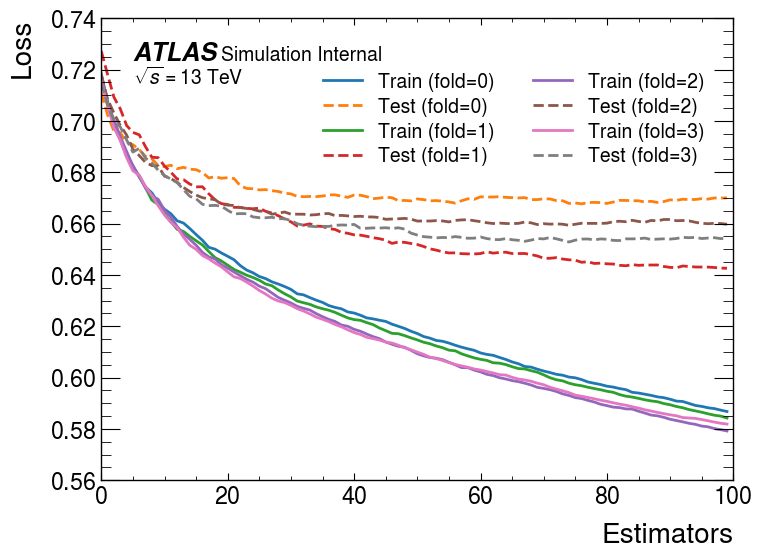

In [22]:
    
    
# Plotting the results
fig, ax = plt.subplots()
for fold in range(nfolds):
    #estimators = range(0, 100)
    estimators = range(0, n_estimators)
    ax.plot(estimators, trainloss[fold], label=f'Train ({fold=})')
    ax.plot(estimators, testloss[fold], label=f'Test ({fold=})', linestyle='--')

ax.legend(title=' ',ncols=2)
ax.set_title('')
mplhep.atlas.label('Internal', data=False, ax=ax)   # true to remove Simulation
ax.set_xlabel('Estimators')
ax.set_ylabel('Loss')
#plt.savefig(f'loss_curve_19vars.pdf')

plt.show()

In [8]:
# Loss curve from pickle file, actual:
#nfolds = 4
#models = []
#
#for fold in range(nfolds):
#    with open(f'CI_test_BDT_binary_Classifier_Classification-BDT_{fold}.pkl', 'rb') as f:
#        model = pickle.load(f)
#        models.append(model)

In [22]:
model.classes_

array([0, 1])

In [23]:
X_sig = df_sig[feature_cols].to_numpy().astype(np.float32) 
X_bkg = df_bkg[feature_cols].to_numpy().astype(np.float32) 

results_sig_list = [model.predict_proba(X_sig)[:,1] for model in models]   #array of bdt scores
results_bkg_list = [model.predict_proba(X_bkg)[:,1] for model in models]   #array of bdt scores

print('Arrays for BDT scroes:')
print('Sig: ',results_sig_list)
print('Bkg: ',results_bkg_list)
print("Length: ", len(results_sig_list))

# Separate into folds
condlist_sig = [df_sig['eventNumber']%nfolds == fold for fold in range(nfolds)]
results_sig = np.select(condlist_sig, results_sig_list)

condlist_bkg = [df_bkg['eventNumber']%nfolds == fold for fold in range(nfolds)]
results_bkg = np.select(condlist_bkg, results_bkg_list)

print('Fold separated arrays for BDT scroes:')
results_sig, results_bkg
print("Length sig: ", len(results_sig))
print("Length bkg: ", len(results_bkg))

Arrays for BDT scroes:
Sig:  [array([0.38470507, 0.6107897 , 0.74128175, ..., 0.6996987 , 0.7840011 ,
       0.4232085 ], dtype=float32), array([0.38084346, 0.64491856, 0.8281398 , ..., 0.64656556, 0.6466758 ,
       0.49305916], dtype=float32), array([0.47967094, 0.66673714, 0.77038604, ..., 0.75205654, 0.7570192 ,
       0.46313927], dtype=float32), array([0.38402313, 0.59649116, 0.7411056 , ..., 0.6643472 , 0.7881384 ,
       0.46128938], dtype=float32)]
Bkg:  [array([0.39310488, 0.5937471 , 0.6949709 , ..., 0.62826705, 0.21447209,
       0.69513667], dtype=float32), array([0.34290212, 0.58381194, 0.64769024, ..., 0.09591258, 0.34787187,
       0.7234801 ], dtype=float32), array([0.611714  , 0.5618843 , 0.54959637, ..., 0.12623632, 0.22885133,
       0.6532288 ], dtype=float32), array([0.43033057, 0.7204953 , 0.6963612 , ..., 0.1260042 , 0.459312  ,
       0.66360044], dtype=float32)]
Length:  4
Fold separated arrays for BDT scroes:
Length sig:  323900
Length bkg:  3959


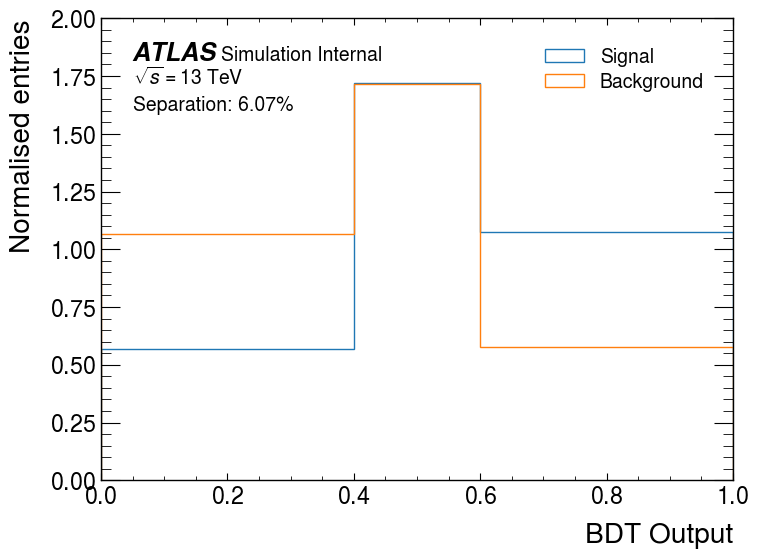

In [24]:

# Define custom bin edges
custom_bins = [0, 0.4, 0.6, 1]

# Histogram plotting
bc_sig, bin_edges, _ = plt.hist(results_sig, weights=df_sig['weight'], bins=custom_bins, histtype='step', density=True, label='Signal')
bc_bkg, _, _ = plt.hist(results_bkg, weights=df_bkg['weight'], bins=custom_bins, histtype='step', density=True, label='Background')

# Calculate bin widths and separation
bin_widths = np.diff(bin_edges)
separation = 0.5 * np.sum(np.nan_to_num(((bc_sig - bc_bkg) ** 2) / (bc_sig + bc_bkg)) * bin_widths)

# Plotting details
plt.legend(loc='upper right')
plt.xlabel('BDT Output')
plt.ylabel('Normalised entries')
plt.text(x=0.05, y=1.6, s=f'Separation: {separation*100:.2f}%')
mplhep.atlas.label('Internal', data=False)   # true to remove Simulation
#plt.savefig(f'separation_fittedbins_19vars.pdf')
plt.legend()


In [30]:

def make_edges(x_sig, x_bkg, n_bins):
    """
    Build bin edges by quantiles of the combined signal+background distribution,
    with a tiny padding to avoid zero‐width bins.
    """
    all_vals = np.concatenate([x_sig, x_bkg])
    qs = np.linspace(0, 1, n_bins + 1)
    edges = np.quantile(all_vals, qs)
    edges[0]  -= 1e-8
    edges[-1] += 1e-8
    return edges

def separation_power(x_sig, w_sig, x_bkg, w_bkg, n_bins=40):
    """
    Compute the TMVA‐style separation power, expressed as a fraction.
    """
    edges = make_edges(x_sig, x_bkg, n_bins)
    # normalized densities
    s_counts, _ = np.histogram(x_sig, bins=edges, weights=w_sig, density=True)
    b_counts, _ = np.histogram(x_bkg, bins=edges, weights=w_bkg, density=True)
    widths = np.diff(edges)

    # compute (s - b)^2 / (s + b), safely handling zeros
    with np.errstate(divide='ignore', invalid='ignore'):
        num  = (s_counts - b_counts)**2
        den  = (s_counts + b_counts)
        frac = np.nan_to_num(num / den)  # zero where den==0
    return 0.5 * np.sum(frac * widths)

# --- USAGE EXAMPLE ---

# Assume you have:
#   df_sig: pandas DataFrame of signal events, with columns=feature_cols + 'weight'
#   df_bkg: pandas DataFrame of background events, with columns=feature_cols + 'weight'
#   feature_cols: list of the feature‐column names

w_sig = df_sig['weight'].to_numpy()
w_bkg = df_bkg['weight'].to_numpy()

separations = {}
for feat in feature_cols:
    x_sig = df_sig[feat].to_numpy()
    x_bkg = df_bkg[feat].to_numpy()
    S_frac = separation_power(x_sig, w_sig, x_bkg, w_bkg, n_bins=10)
    separations[feat] = S_frac * 100.0   # convert to percentage

# print features sorted by descending separation
for feat, S_pct in sorted(separations.items(), key=lambda kv: kv[1], reverse=True):
    print(f"{feat:20s} separation = {S_pct:6.2f}%")


ph_conversion_type[:,0] separation =   2.04%
dr_ph                separation =   1.94%
ph_eta[:,1]          separation =   1.75%
ph_mlph_closest[:,1] separation =   1.48%
diph_M               separation =   1.35%
jet_pt[:,0]          separation =   1.32%
dr_lep_ph1           separation =   1.19%
ph_eta[:,0]          separation =   1.14%
jet_pt[:,1]          separation =   0.69%
dr_lep_ph0           separation =   0.67%
jet_tagWeightBin_DL1r_Continuous_Max separation =   0.57%
m_AllObjects         separation =   0.56%
met_met              separation =   0.55%
ph_mphb70_closest[:,0] separation =   0.51%
ph_mlph_closest[:,0] separation =   0.51%
ph_pt[:,0]           separation =   0.43%
ph_mphb70_closest[:,1] separation =   0.30%
ph_pt[:,1]           separation =   0.24%
event_nbjets70       separation =   0.17%


sig histogram values:  [0.00515428 0.23281972 0.77336752 1.25568342 1.58730469 1.84812703
 1.90868208 1.60170593 0.74491617 0.04223901]
bkg histogram values:  [0.0521865  0.79951133 1.61279936 1.80378816 1.88734069 1.53980429
 1.39029182 0.69322502 0.21847681 0.0025761 ]


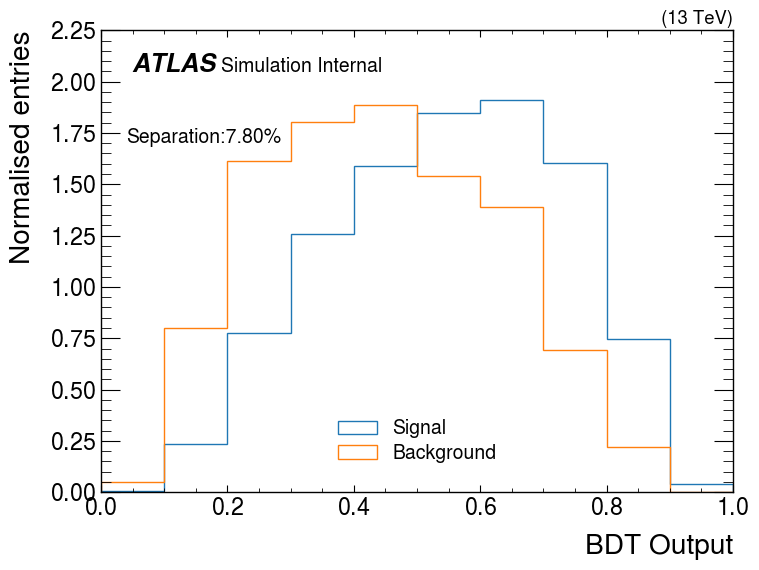

In [52]:
# Considering Negative Weights

bc_sig,_,_ = plt.hist(results_sig, weights=(df_sig['weight']),  range=(0,1), bins=nbins, histtype='step', density=True, label='Signal')
bc_bkg,_,_ = plt.hist(results_bkg, weights=(df_bkg['weight']), range=(0,1), bins=nbins, histtype='step', density=True, label='Background')
print('sig histogram values: ',bc_sig )
print('bkg histogram values: ',bc_bkg )

separation = 0.5 * np.sum(np.nan_to_num(((bc_sig/nbins - bc_bkg/nbins) ** 2) / (bc_sig/nbins + bc_bkg/nbins)))

mplhep.atlas.label('Work In Progress', data=False, ax=ax)
plt.legend(loc='upper right')
plt.xlabel('BDT Output')
plt.ylabel('Normalised entries')
plt.text(x=0.04, y=1.7,s=F'Separation:{separation*100:.2f}%')
mplhep.atlas.label('Internal', data=False, loc=1)   # true to remove Simulation
plt.savefig(f'separation_10bins_19vars.pdf')
plt.legend()

# DPG 2025 slides

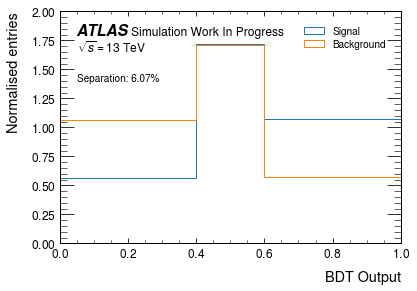

In [24]:

# Define custom bin edges
custom_bins = [0, 0.4, 0.6, 1]

# Create figure and axis explicitly
fig, ax = plt.subplots()

# Histogram plotting
bc_sig, bin_edges, _ = ax.hist(results_sig, weights=df_sig['weight'], bins=custom_bins, histtype='step', density=True, label='Signal')
bc_bkg, _, _ = ax.hist(results_bkg, weights=df_bkg['weight'], bins=custom_bins, histtype='step', density=True, label='Background')


# Calculate bin widths and separation
bin_widths = np.diff(bin_edges)
separation = 0.5 * np.sum(np.nan_to_num(((bc_sig - bc_bkg) ** 2) / (bc_sig + bc_bkg)) * bin_widths)


mplhep.atlas.label('Work In Progress', data=False, ax=ax, fontsize=12)  # Explicitly pass ax

# Plotting details
ax.legend(loc='upper right')
ax.set_xlabel('BDT Output')
ax.set_ylabel('Normalised entries')
ax.text(x=0.05, y=1.4, s=f'Separation: {separation*100:.2f}%')
plt.show()

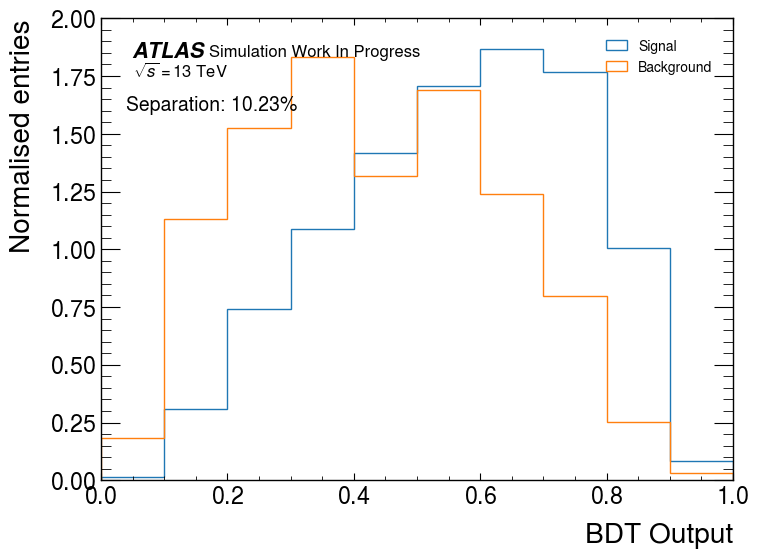

In [31]:

# Create figure and axis explicitly
fig, ax = plt.subplots()

# Plot histograms
bc_sig, _, _ = ax.hist(results_sig, weights=df_sig['weight'], range=(0,1), bins=nbins, 
                        histtype='step', density=True, label='Signal')
bc_bkg, _, _ = ax.hist(results_bkg, weights=df_bkg['weight'], range=(0,1), bins=nbins, 
                        histtype='step', density=True, label='Background')

# Compute separation
separation = 0.5 * np.sum(np.nan_to_num(((bc_sig/nbins - bc_bkg/nbins) ** 2) / (bc_sig/nbins + bc_bkg/nbins)))

# Apply ATLAS label
mplhep.atlas.label('Work In Progress', data=False, ax=ax, fontsize=12)  # Explicitly pass ax

# Labels and text
#ax.legend(loc='upper right')
ax.legend(loc='upper right', fontsize=10, labelspacing=0.5, handlelength=1.5)
ax.set_xlabel('BDT Output')
ax.set_ylabel('Normalised entries')
ax.text(0.04, 1.6, f'Separation: {separation*100:.2f}%')

# Show or save figure
# plt.savefig('separation.pdf')
plt.show()

In [28]:
# Define the custom formatter function
def custom_formatter(x, pos):
    return f'{x * 0.1:.1f}'

In [ ]:
## !!!! KS test with fitted bins

# Working code - Per fold. Change no. of folds
# Unweighted  - with corrected Sumw2()
# Normalized with auc
folds = 4
fold = 2
fig, axes = plt.subplots(nrows=2,ncols=1,gridspec_kw={'height_ratios': [3, 1]}, sharex=True)
custom_bins = [0, 0.39, 0.6, 1]


# Example dummy data and plots:
results_sig_fold_test = results_sig_85_reweighted[df_sig_85_reweighted['eventNumber']%folds == fold]
results_bkg_fold_test = results_bkg_85_reweighted[df_bkg_85_reweighted['eventNumber']%folds == fold]
weights_sig_fold_test = df_sig_85_reweighted['weight'][df_sig_85_reweighted['eventNumber']%folds == fold]
weights_bkg_fold_test = df_bkg_85_reweighted['weight'][df_bkg_85_reweighted['eventNumber']%folds == fold]
y = np.concatenate([np.ones_like(results_sig_fold_test), np.zeros_like(results_bkg_fold_test)])
scores = np.concatenate([results_sig_fold_test, results_bkg_fold_test])
weights = np.concatenate([weights_sig_fold_test,weights_bkg_fold_test])

results_sig_fold_train = results_sig_85_reweighted[df_sig_85_reweighted['eventNumber']%folds != fold]
results_bkg_fold_train = results_bkg_85_reweighted[df_bkg_85_reweighted['eventNumber']%folds != fold]
weights_sig_fold_train = df_sig_85_reweighted['weight'][df_sig_85_reweighted['eventNumber']%folds != fold]
weights_bkg_fold_train = df_bkg_85_reweighted['weight'][df_bkg_85_reweighted['eventNumber']%folds != fold]
y = np.concatenate([np.ones_like(results_sig_fold_train), np.zeros_like(results_bkg_fold_train)])
scores = np.concatenate([results_sig_fold_train, results_bkg_fold_train])
weights = np.concatenate([weights_sig_fold_train,weights_bkg_fold_train])

"""
bc, bb = np.histogram(data1, weights=weights1, range=(-3,3), bins=10)
sumW2, bb = np.histogram(data1, weights=weights1**2, range=(-3,3), bins=10)
mplhep.histplot(bc,bb,yerr=np.sqrt(sumW2),density=True,label='10000 events, weight=0.1', histtype='errorbar')
"""
#bc_sig_train, bb = np.histogram(results_sig_fold_train, weights=weights_sig_fold_train, bins=np.linspace(0,1,11), density=True)


bc_sig_train, bb = np.histogram(results_sig_fold_train, weights=weights_sig_fold_train, range=(0,1), bins=custom_bins, density=True)
total_sig_train = len(results_sig_fold_train) #np.sum(bc_sig_train)
sumW2, bb = np.histogram(results_sig_fold_train, weights=weights_sig_fold_train**2, range=(0,1), bins=custom_bins)
mplhep.histplot(bc_sig_train,bb,yerr=np.sqrt(sumW2), density=True, label='sig (train)', histtype='step', ax=axes[0], color='red', alpha=0.3, linewidth=4)
bc_sig_train_e = np.sqrt(sumW2)

bc_sig_test, bb = np.histogram(results_sig_fold_test,  weights=weights_sig_fold_test, range=(0,1), bins=custom_bins, density=True)
total_sig_test = len(results_sig_fold_test) #np.sum(bc_sig_test)
sumW2, bb = np.histogram(results_sig_fold_test, weights=weights_sig_fold_test**2, range=(0,1), bins=custom_bins)
mplhep.histplot(bc_sig_test,bb,yerr=np.sqrt(sumW2),density=True, label='sig (test)', histtype='errorbar', ax=axes[0], color='red', markersize=7)
bc_sig_test_e = np.sqrt(sumW2)

bc_bkg_train, bb = np.histogram(results_bkg_fold_train, weights=weights_bkg_fold_train, range=(0,1), bins=custom_bins, density=True)
total_bkg_train = len(results_bkg_fold_train) #np.sum(bc_sig_train)
sumW2, bb = np.histogram(results_bkg_fold_train, weights=weights_bkg_fold_train**2, range=(0,1), bins=custom_bins)
mplhep.histplot(bc_bkg_train,bb,yerr=np.sqrt(sumW2), density=True, label='bkg (train)', histtype='step', ax=axes[0], color='blue', alpha=0.3, linewidth=4)
bc_bkg_train_e = np.sqrt(sumW2)


bc_bkg_test, bb = np.histogram(results_bkg_fold_test,  weights=weights_bkg_fold_test, range=(0,1), bins=custom_bins, density=True)
total_bkg_test = len(results_bkg_fold_test) #np.sum(bc_sig_test)
sumW2, bb = np.histogram(results_bkg_fold_test, weights=weights_bkg_fold_test**2, range=(0,1), bins=custom_bins)
mplhep.histplot(bc_bkg_test,bb,yerr=np.sqrt(sumW2), density=True, label='bkg (test)', histtype='errorbar', ax=axes[0], color='blue', markersize=7)
bc_bkg_test_e = np.sqrt(sumW2)

print(bb)


print("-----------------------------------------------")
# Example check if data is within expected range
print(bc_sig_train.min(), bc_sig_train.max())
print(bc_sig_test.min(), bc_sig_test.max())

print(len(bb), len(bc_sig_train), len(bc_bkg_train))
bc_bkg_test = np.where(bc_bkg_test == 0, 1e-1, bc_bkg_test)


corr_factor_sig = np.sum(bc_sig_train)/np.sum(bc_sig_test)
chi2_sig, p_sig = chisquare(bc_sig_train, bc_sig_test*corr_factor_sig)
corr_factor_bkg = np.sum(bc_bkg_train)/np.sum(bc_bkg_test)
chi2_bkg, p_bkg = chisquare(bc_bkg_train, bc_bkg_test*corr_factor_bkg)


axes[0].set_xlim(0,1)
axes[0].set_ylim(0,4)

#scale_and_format_y_axis(axes[0], scale_factor=0.1)  # Adjust scale_factor as needed

# Create the FuncFormatter object
formatter = mtick.FuncFormatter(custom_formatter)

# Apply the custom formatter to the y-axis
axes[0].yaxis.set_major_formatter(formatter)
axes[0].yaxis.set_major_locator(mtick.MultipleLocator(1))   # removing this will lead to duplicate labels


axes[0].legend(title=F'Fold={fold}', loc='upper right')

#ax.set_xlabel('BDT score')
axes[0].set_ylabel('Fraction of events', labelpad=20)
mplhep.atlas.label('Internal', data=False, ax=axes[0])
axes[0].text(x=0.05, y=2.6,s=F'Signal: $\chi^2$ $p$-value={p_sig:.2f}\nBkg:     $\chi^2$ $p$-value={p_bkg:.2f}')
axes[0].tick_params(axis='both', labelsize=10)

print("Signal train histogram:", bc_sig_train)
print("Signal test histogram:", bc_sig_test)
print("Background train histogram:", bc_bkg_train)
print("Background test histogram:", bc_bkg_test)

print("-----------------------------------------------")




print("\nSignal train errors:", bc_sig_train_e)
print("Signal test errors:", bc_sig_test_e)
print("Background train errors:", bc_bkg_train_e)
print("Background test errors:", bc_bkg_test_e)

print("-----------------------------------------------")

ratio_sig = np.where(bc_sig_test == 0, 1, bc_sig_train / bc_sig_test)
ratio_bkg = np.where(bc_bkg_test == 0, 1, bc_bkg_train / bc_bkg_test)


print("\nSig ratio: ", ratio_sig)
print("Bkg ratio: ", ratio_bkg)


ratio_sig_e = np.sqrt((bc_sig_train/(1.0*bc_sig_test*bc_sig_test))*(bc_sig_train/(1.0*bc_sig_test*bc_sig_test))*bc_sig_test_e*bc_sig_test_e+(1/(1.0*bc_sig_test))*(1/(1.0*bc_sig_test))*bc_sig_train_e*bc_sig_train_e)
ratio_bkg_e = np.sqrt((bc_bkg_train/(1.0*bc_bkg_test*bc_bkg_test))*(bc_bkg_train/(1.0*bc_bkg_test*bc_bkg_test))*bc_bkg_test_e*bc_bkg_test_e+(1/(1.0*bc_bkg_test))*(1/(1.0*bc_bkg_test))*bc_bkg_train_e*bc_bkg_train_e)

print("\nSig Ratio uncertainties per bin: ", ratio_sig_e)



# Clip errors and add padding
max_error = 100  # Example maximum error threshold
clipped_errors_sig = np.clip(ratio_sig_e, 0, max_error)
clipped_errors_bkg = np.clip(ratio_bkg_e, 0, max_error)

print("Clipped errors:", clipped_errors_sig)
print("Clipped errors:", clipped_errors_bkg)

custom_bins = np.array([0, 0.382, 0.6, 1])


#bb_centers = (bb[:-1] + bb[1:]) / 2
bb_centers = (custom_bins[:-1] + custom_bins[1:]) / 2

mplhep.histplot(ratio_sig, custom_bins, histtype='step', ax=axes[1], color='red', linewidth=2)
mplhep.histplot(ratio_bkg, custom_bins, histtype='step', ax=axes[1], color='blue', linewidth=2)

#bin_width = bb[1] - bb[0] 
#bin_width = custom_bins[1] - custom_bins[0]  # Update bin width based on custom bins
bin_widths = np.diff(custom_bins)  # Using np.diff to calculate the distance between bin edges
print(bin_widths)

    
# Plot the uncertainty band using custom bin centers and the clipped errors
for center, err, width in zip(bb_centers, clipped_errors_sig, bin_widths):
    axes[1].bar(center, 2 * err, width=width, bottom=1 - err, color='red', alpha=0.1, edgecolor='red', hatch='\\\\', align='center')

for center, err, width in zip(bb_centers, clipped_errors_bkg, bin_widths):
    axes[1].bar(center, 2 * err, width=width, bottom=1 - err, color='blue', alpha=0.1, edgecolor='blue', hatch='\\\\', align='center')


#axes[1].set_dashes((5,2))

axes[1].axhline(1,0,1,linestyle='--',color='grey', linewidth=1)
axes[1].set_ylabel('train/test')
axes[1].set_xlabel('BDT score')
axes[1].tick_params(axis='both', labelsize=10)

axes[1].set_ylim(0.1,1.9)  # Adjust based on your ratio values
fig.tight_layout()
fig.subplots_adjust(hspace=0.02)
#fig.savefig(f'Test_Train_Chi_Squared_Unweighted_{fold}_Model7_85To70PerProcess_fittedBins.png')

-----------------------------------------------
0.5665195812066991 1.7219006872405933
0.567465984792416 1.705164320278917
4 3 3
Signal train histogram: [0.56651958 1.72190069 1.07253008]
Signal test histogram: [0.56746598 1.70516432 1.07995186]
Background train histogram: [1.08979686 1.71643339 0.55198645]
Background test histogram: [1.00625506 1.70591629 0.64078679]
-----------------------------------------------

Signal train errors: [0.03099773 0.038172   0.04242804]
Signal test errors: [0.01789207 0.02195039 0.02460513]
Background train errors: [0.6169462  0.58709514 0.3880698 ]
Background test errors: [0.4681576  0.33479622 0.38675627]
-----------------------------------------------

Sig ratio:  [0.99833223 1.00981511 0.99312768]
Bkg ratio:  [1.08302248 1.00616507 0.86141983]

Sig Ratio uncertainties per bin:  [0.06304509 0.02588664 0.04533702]
Clipped errors: [0.06304509 0.02588664 0.04533702]
Clipped errors: [0.79359545 0.39677907 0.79817823]
[0.4 0.2 0.4]


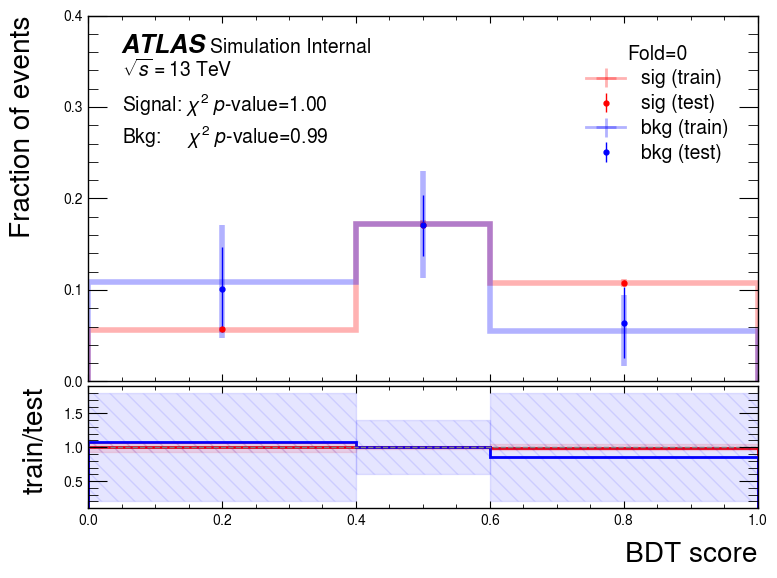

In [32]:
## !!!! KS test with fitted bins

# Working code - Per fold. Change no. of folds
# Unweighted  - with corrected Sumw2()
# Normalized with auc
folds = 4
fold = 0
fig, axes = plt.subplots(nrows=2,ncols=1,gridspec_kw={'height_ratios': [3, 1]}, sharex=True)
custom_bins = [0, 0.4, 0.6, 1]


# Example dummy data and plots:
results_sig_fold_test = results_sig[df_sig['eventNumber']%folds == fold]
results_bkg_fold_test = results_bkg[df_bkg['eventNumber']%folds == fold]
weights_sig_fold_test = df_sig['weight'][df_sig['eventNumber']%folds == fold]
weights_bkg_fold_test = df_bkg['weight'][df_bkg['eventNumber']%folds == fold]
y = np.concatenate([np.ones_like(results_sig_fold_test), np.zeros_like(results_bkg_fold_test)])
scores = np.concatenate([results_sig_fold_test, results_bkg_fold_test])
weights = np.concatenate([weights_sig_fold_test,weights_bkg_fold_test])

results_sig_fold_train = results_sig[df_sig['eventNumber']%folds != fold]
results_bkg_fold_train = results_bkg[df_bkg['eventNumber']%folds != fold]
weights_sig_fold_train = df_sig['weight'][df_sig['eventNumber']%folds != fold]
weights_bkg_fold_train = df_bkg['weight'][df_bkg['eventNumber']%folds != fold]
y = np.concatenate([np.ones_like(results_sig_fold_train), np.zeros_like(results_bkg_fold_train)])
scores = np.concatenate([results_sig_fold_train, results_bkg_fold_train])
weights = np.concatenate([weights_sig_fold_train,weights_bkg_fold_train])

"""
bc, bb = np.histogram(data1, weights=weights1, range=(-3,3), bins=10)
sumW2, bb = np.histogram(data1, weights=weights1**2, range=(-3,3), bins=10)
mplhep.histplot(bc,bb,yerr=np.sqrt(sumW2),density=True,label='10000 events, weight=0.1', histtype='errorbar')
"""
#bc_sig_train, bb = np.histogram(results_sig_fold_train, weights=weights_sig_fold_train, bins=np.linspace(0,1,11), density=True)


bc_sig_train, bb = np.histogram(results_sig_fold_train, weights=weights_sig_fold_train, range=(0,1), bins=custom_bins, density=True)
total_sig_train = len(results_sig_fold_train) #np.sum(bc_sig_train)
sumW2, bb = np.histogram(results_sig_fold_train, weights=weights_sig_fold_train**2, range=(0,1), bins=custom_bins)
mplhep.histplot(bc_sig_train,bb,yerr=np.sqrt(sumW2), density=True, label='sig (train)', histtype='step', ax=axes[0], color='red', alpha=0.3, linewidth=4)
bc_sig_train_e = np.sqrt(sumW2)

bc_sig_test, bb = np.histogram(results_sig_fold_test,  weights=weights_sig_fold_test, range=(0,1), bins=custom_bins, density=True)
total_sig_test = len(results_sig_fold_test) #np.sum(bc_sig_test)
sumW2, bb = np.histogram(results_sig_fold_test, weights=weights_sig_fold_test**2, range=(0,1), bins=custom_bins)
mplhep.histplot(bc_sig_test,bb,yerr=np.sqrt(sumW2),density=True, label='sig (test)', histtype='errorbar', ax=axes[0], color='red', markersize=7)
bc_sig_test_e = np.sqrt(sumW2)

bc_bkg_train, bb = np.histogram(results_bkg_fold_train, weights=weights_bkg_fold_train, range=(0,1), bins=custom_bins, density=True)
total_bkg_train = len(results_bkg_fold_train) #np.sum(bc_sig_train)
sumW2, bb = np.histogram(results_bkg_fold_train, weights=weights_bkg_fold_train**2, range=(0,1), bins=custom_bins)
mplhep.histplot(bc_bkg_train,bb,yerr=np.sqrt(sumW2), density=True, label='bkg (train)', histtype='step', ax=axes[0], color='blue', alpha=0.3, linewidth=4)
bc_bkg_train_e = np.sqrt(sumW2)


bc_bkg_test, bb = np.histogram(results_bkg_fold_test,  weights=weights_bkg_fold_test, range=(0,1), bins=custom_bins, density=True)
total_bkg_test = len(results_bkg_fold_test) #np.sum(bc_sig_test)
sumW2, bb = np.histogram(results_bkg_fold_test, weights=weights_bkg_fold_test**2, range=(0,1), bins=custom_bins)
mplhep.histplot(bc_bkg_test,bb,yerr=np.sqrt(sumW2), density=True, label='bkg (test)', histtype='errorbar', ax=axes[0], color='blue', markersize=7)
bc_bkg_test_e = np.sqrt(sumW2)




print("-----------------------------------------------")
# Example check if data is within expected range
print(bc_sig_train.min(), bc_sig_train.max())
print(bc_sig_test.min(), bc_sig_test.max())

print(len(bb), len(bc_sig_train), len(bc_bkg_train))
bc_bkg_test = np.where(bc_bkg_test == 0, 1e-1, bc_bkg_test)


corr_factor_sig = np.sum(bc_sig_train)/np.sum(bc_sig_test)
chi2_sig, p_sig = chisquare(bc_sig_train, bc_sig_test*corr_factor_sig)
corr_factor_bkg = np.sum(bc_bkg_train)/np.sum(bc_bkg_test)
chi2_bkg, p_bkg = chisquare(bc_bkg_train, bc_bkg_test*corr_factor_bkg)


axes[0].set_xlim(0,1)
axes[0].set_ylim(0,4)

#scale_and_format_y_axis(axes[0], scale_factor=0.1)  # Adjust scale_factor as needed

# Create the FuncFormatter object
formatter = mtick.FuncFormatter(custom_formatter)

# Apply the custom formatter to the y-axis
axes[0].yaxis.set_major_formatter(formatter)
axes[0].yaxis.set_major_locator(mtick.MultipleLocator(1))   # removing this will lead to duplicate labels


axes[0].legend(title=F'Fold={fold}', loc='upper right')

#ax.set_xlabel('BDT score')
axes[0].set_ylabel('Fraction of events', labelpad=20)
mplhep.atlas.label('Internal', data=False, ax=axes[0])
axes[0].text(x=0.05, y=2.6,s=F'Signal: $\chi^2$ $p$-value={p_sig:.2f}\nBkg:     $\chi^2$ $p$-value={p_bkg:.2f}')
axes[0].tick_params(axis='both', labelsize=10)

print("Signal train histogram:", bc_sig_train)
print("Signal test histogram:", bc_sig_test)
print("Background train histogram:", bc_bkg_train)
print("Background test histogram:", bc_bkg_test)

print("-----------------------------------------------")





print("\nSignal train errors:", bc_sig_train_e)
print("Signal test errors:", bc_sig_test_e)
print("Background train errors:", bc_bkg_train_e)
print("Background test errors:", bc_bkg_test_e)

print("-----------------------------------------------")

ratio_sig = np.where(bc_sig_test == 0, 1, bc_sig_train / bc_sig_test)
ratio_bkg = np.where(bc_bkg_test == 0, 1, bc_bkg_train / bc_bkg_test)


print("\nSig ratio: ", ratio_sig)
print("Bkg ratio: ", ratio_bkg)


ratio_sig_e = np.sqrt((bc_sig_train/(1.0*bc_sig_test*bc_sig_test))*(bc_sig_train/(1.0*bc_sig_test*bc_sig_test))*bc_sig_test_e*bc_sig_test_e+(1/(1.0*bc_sig_test))*(1/(1.0*bc_sig_test))*bc_sig_train_e*bc_sig_train_e)
ratio_bkg_e = np.sqrt((bc_bkg_train/(1.0*bc_bkg_test*bc_bkg_test))*(bc_bkg_train/(1.0*bc_bkg_test*bc_bkg_test))*bc_bkg_test_e*bc_bkg_test_e+(1/(1.0*bc_bkg_test))*(1/(1.0*bc_bkg_test))*bc_bkg_train_e*bc_bkg_train_e)

print("\nSig Ratio uncertainties per bin: ", ratio_sig_e)




# Clip errors and add padding
max_error = 100  # Example maximum error threshold
clipped_errors_sig = np.clip(ratio_sig_e, 0, max_error)
clipped_errors_bkg = np.clip(ratio_bkg_e, 0, max_error)

print("Clipped errors:", clipped_errors_sig)
print("Clipped errors:", clipped_errors_bkg)

custom_bins = np.array([0, 0.4, 0.6, 1])


#bb_centers = (bb[:-1] + bb[1:]) / 2
bb_centers = (custom_bins[:-1] + custom_bins[1:]) / 2

mplhep.histplot(ratio_sig, custom_bins, histtype='step', ax=axes[1], color='red', linewidth=2)
mplhep.histplot(ratio_bkg, custom_bins, histtype='step', ax=axes[1], color='blue', linewidth=2)

#bin_width = bb[1] - bb[0] 
#bin_width = custom_bins[1] - custom_bins[0]  # Update bin width based on custom bins
bin_widths = np.diff(custom_bins)  # Using np.diff to calculate the distance between bin edges
print(bin_widths)

    
# Plot the uncertainty band using custom bin centers and the clipped errors
for center, err, width in zip(bb_centers, clipped_errors_sig, bin_widths):
    axes[1].bar(center, 2 * err, width=width, bottom=1 - err, color='red', alpha=0.1, edgecolor='red', hatch='\\\\', align='center')

for center, err, width in zip(bb_centers, clipped_errors_bkg, bin_widths):
    axes[1].bar(center, 2 * err, width=width, bottom=1 - err, color='blue', alpha=0.1, edgecolor='blue', hatch='\\\\', align='center')


#axes[1].set_dashes((5,2))

axes[1].axhline(1,0,1,linestyle='--',color='grey', linewidth=1)
axes[1].set_ylabel('train/test')
axes[1].set_xlabel('BDT score')
axes[1].tick_params(axis='both', labelsize=10)

axes[1].set_ylim(0.1,1.9)  # Adjust based on your ratio values
fig.tight_layout()
fig.subplots_adjust(hspace=0.02)
#fig.savefig(f'Test_Train_Chi_Squared_Unweighted_{fold}_Model6_fittedbins_19vars.png')

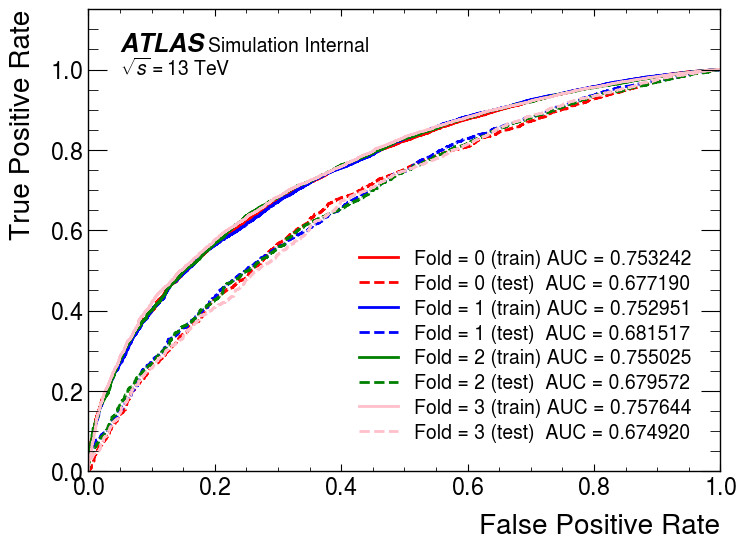

In [54]:
# Maybe corrected ROC curves? Checking...

nfolds = 4

colors = ['red','blue','green','pink'] 
for fold in range(nfolds):
    X_sig_train = df_sig[feature_cols][df_sig['eventNumber']%nfolds != fold]
    X_sig_test = df_sig[feature_cols][df_sig['eventNumber']%nfolds == fold]
    X_bkg_train = df_bkg[feature_cols][df_bkg['eventNumber']%nfolds != fold]
    X_bkg_test = df_bkg[feature_cols][df_bkg['eventNumber']%nfolds == fold]
    results_sig_fold_train = models[fold].predict_proba(X_sig_train)[:,1]
    results_bkg_fold_train = models[fold].predict_proba(X_bkg_train)[:,1]
    results_sig_fold_test = models[fold].predict_proba(X_sig_test)[:,1]
    results_bkg_fold_test = models[fold].predict_proba(X_bkg_test)[:,1]

    y = np.concatenate([np.ones_like(results_sig_fold_train), np.zeros_like(results_bkg_fold_train)])
    scores = np.concatenate([results_sig_fold_train, results_bkg_fold_train])
    fpr, tpr, thresholds = metrics.roc_curve(y, scores, pos_label=1)
    AUC = metrics.roc_auc_score(y, scores)
    plt.plot(fpr,tpr,label=F'Fold = {fold} (train) AUC = {AUC:.6f}', color=colors[fold])
    
    y = np.concatenate([np.ones_like(results_sig_fold_test), np.zeros_like(results_bkg_fold_test)])
    scores = np.concatenate([results_sig_fold_test, results_bkg_fold_test])
    fpr, tpr, thresholds = metrics.roc_curve(y, scores, pos_label=1)
    AUC = metrics.roc_auc_score(y, scores)
    plt.plot(fpr,tpr,label=F'Fold = {fold} (test)  AUC = {AUC:.6f}', color=colors[fold], linestyle='--')

plt.legend()
plt.xlim(0,1)
plt.ylim(0,1.15)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
mplhep.atlas.label('Internal', data=False)
plt.savefig('auc_19vars.pdf')

Features with Average Importance (Descending):
Feature Name: ph_conversion_type[:,0], Average Importance: 0.2261391580104828
Feature Name: ph_mlph_closest[:,1], Average Importance: 0.09982526954263449
Feature Name: dr_lep_ph1, Average Importance: 0.0683745052665472
Feature Name: ph_eta[:,1], Average Importance: 0.06300494074821472
Feature Name: dr_lep_ph0, Average Importance: 0.05268146190792322
Feature Name: event_nbjets70, Average Importance: 0.044096448458731174
Feature Name: ph_mlph_closest[:,0], Average Importance: 0.04177076416090131
Feature Name: ph_mphb70_closest[:,1], Average Importance: 0.04120528604835272
Feature Name: ph_eta[:,0], Average Importance: 0.04047429282218218
Feature Name: dr_ph, Average Importance: 0.039501559920609
Feature Name: ph_mphb70_closest[:,0], Average Importance: 0.0390129154548049
Feature Name: jet_pt[:,1], Average Importance: 0.037856741808354855
Feature Name: jet_pt[:,0], Average Importance: 0.033852691762149334
Feature Name: met_met, Average Import

<Figure size 1200x800 with 0 Axes>

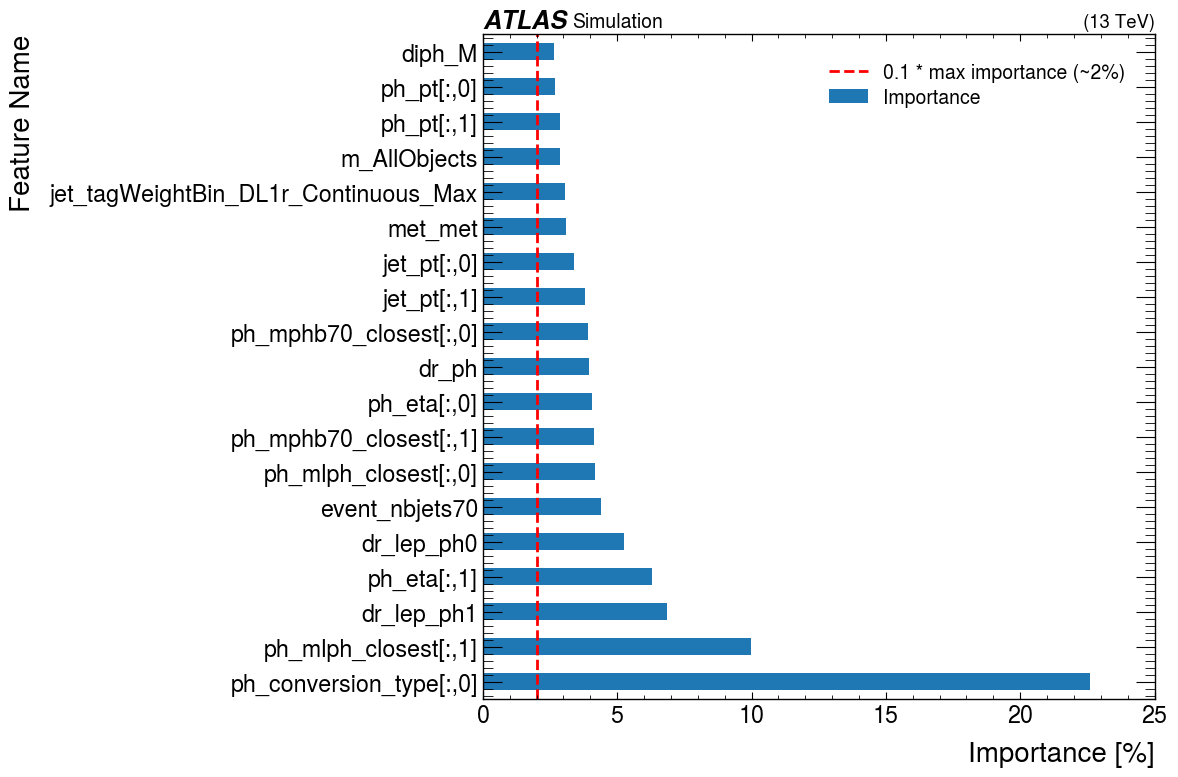

In [64]:
import matplotlib.pyplot as plt
import pandas as pd

def average_feature_importances(models, feature_cols):
  """
  This function calculates the average importance for each feature across all folds/models.

  Args:
      models: A list of XGBoost classifier models.
      feature_cols: A list of feature column names.

  Returns:
      A dictionary containing feature name and its average importance across all folds.
  """
  # Initialize a dictionary to store average importance
  average_importances = {feature: 0.0 for feature in feature_cols}

  # Iterate through each model and accumulate importance for each feature
  for model in models:
    importance_scores = model.feature_importances_  # Access feature importance attribute
    for feature, importance in zip(feature_cols, importance_scores):
      average_importances[feature] += importance

  # Calculate average importance by dividing by the total number of models
  num_models = len(models)
  for feature in average_importances:
    average_importances[feature] /= num_models

  # Sort features by importance in descending order
  sorted_importances = sorted(average_importances.items(), key=lambda x: x[1], reverse=True)
  return sorted_importances

# Assuming models and feature_cols are available (replace with your actual data)
average_importances = average_feature_importances(models, feature_cols)

# Print features with average importance (sorted by descending importance)
print("Features with Average Importance (Descending):")
for feature, importance in average_importances:
  print(f"Feature Name: {feature}, Average Importance: {importance}")

# Create DataFrame from sorted importance and plot as horizontal bar chart
importance_df = pd.DataFrame(average_importances, columns=['Feature', 'Importance'])
importance_df['Importance'] *= 100  # Scale importance to percentage

plt.figure(figsize=(12, 8))
importance_df.set_index('Feature').plot.barh(legend=False, figsize=(12, 8))
plt.xlabel('Importance [%]', fontsize=20)
plt.ylabel('Feature Name', fontsize=20)

# Optional: Add a threshold line (adjust threshold value as needed)
plt.axvline(2.0, color='red', linestyle='--', label='0.1 * max importance (~2%)')
plt.legend()
mplhep.atlas.label(data=False, loc=0)
plt.savefig(f'Feature_importance_average_Model6_19vars.pdf')

plt.tight_layout()
plt.show()


In [105]:
for i, model in enumerate(models):
    # Assuming model[0] has the feature importance scores
    feature_importances = models[i].feature_importances_

    # Create a list of tuples with feature name and importance
    feature_imp_list = zip(feature_cols, feature_importances)
    print(feature_imp_list) 
    # Sort the list based on importance in ascending order (key=lambda x: x[1])
    sorted_features = sorted(feature_imp_list, key=lambda x: x[1])
    print(f'for model: {i}')
    # Print the sorted features
    for feature, importance in sorted_features:
        print(f"Feature Name: {feature}, Importance: {importance}")
        
    print(F"No. of features: {len(sorted_features)}")

for model: 0
Feature Name: diph_M, Importance: 0.020778506994247437
Feature Name: m_AllObjects, Importance: 0.02209719642996788
Feature Name: ph_pt[:,0], Importance: 0.022784927859902382
Feature Name: ph_mlph_closest[:,0], Importance: 0.023761354386806488
Feature Name: jet_pt[:,0], Importance: 0.025089861825108528
Feature Name: ph_pt[:,1], Importance: 0.02620004117488861
Feature Name: met_met, Importance: 0.026568641886115074
Feature Name: jet_DL1r_bjetscore, Importance: 0.026715319603681564
Feature Name: ph_mphb70_closest[:,1], Importance: 0.027384640648961067
Feature Name: ph_eta[:,0], Importance: 0.030024560168385506
Feature Name: ph_mphb70_closest[:,0], Importance: 0.030101966112852097
Feature Name: jet_pt[:,1], Importance: 0.03012244589626789
Feature Name: dr_ph, Importance: 0.03096022829413414
Feature Name: ph_eta[:,1], Importance: 0.04277438297867775
Feature Name: dr_lep_ph0, Importance: 0.04580411687493324
Feature Name: ph_mlph_closest[:,1], Importance: 0.051252223551273346
Fea

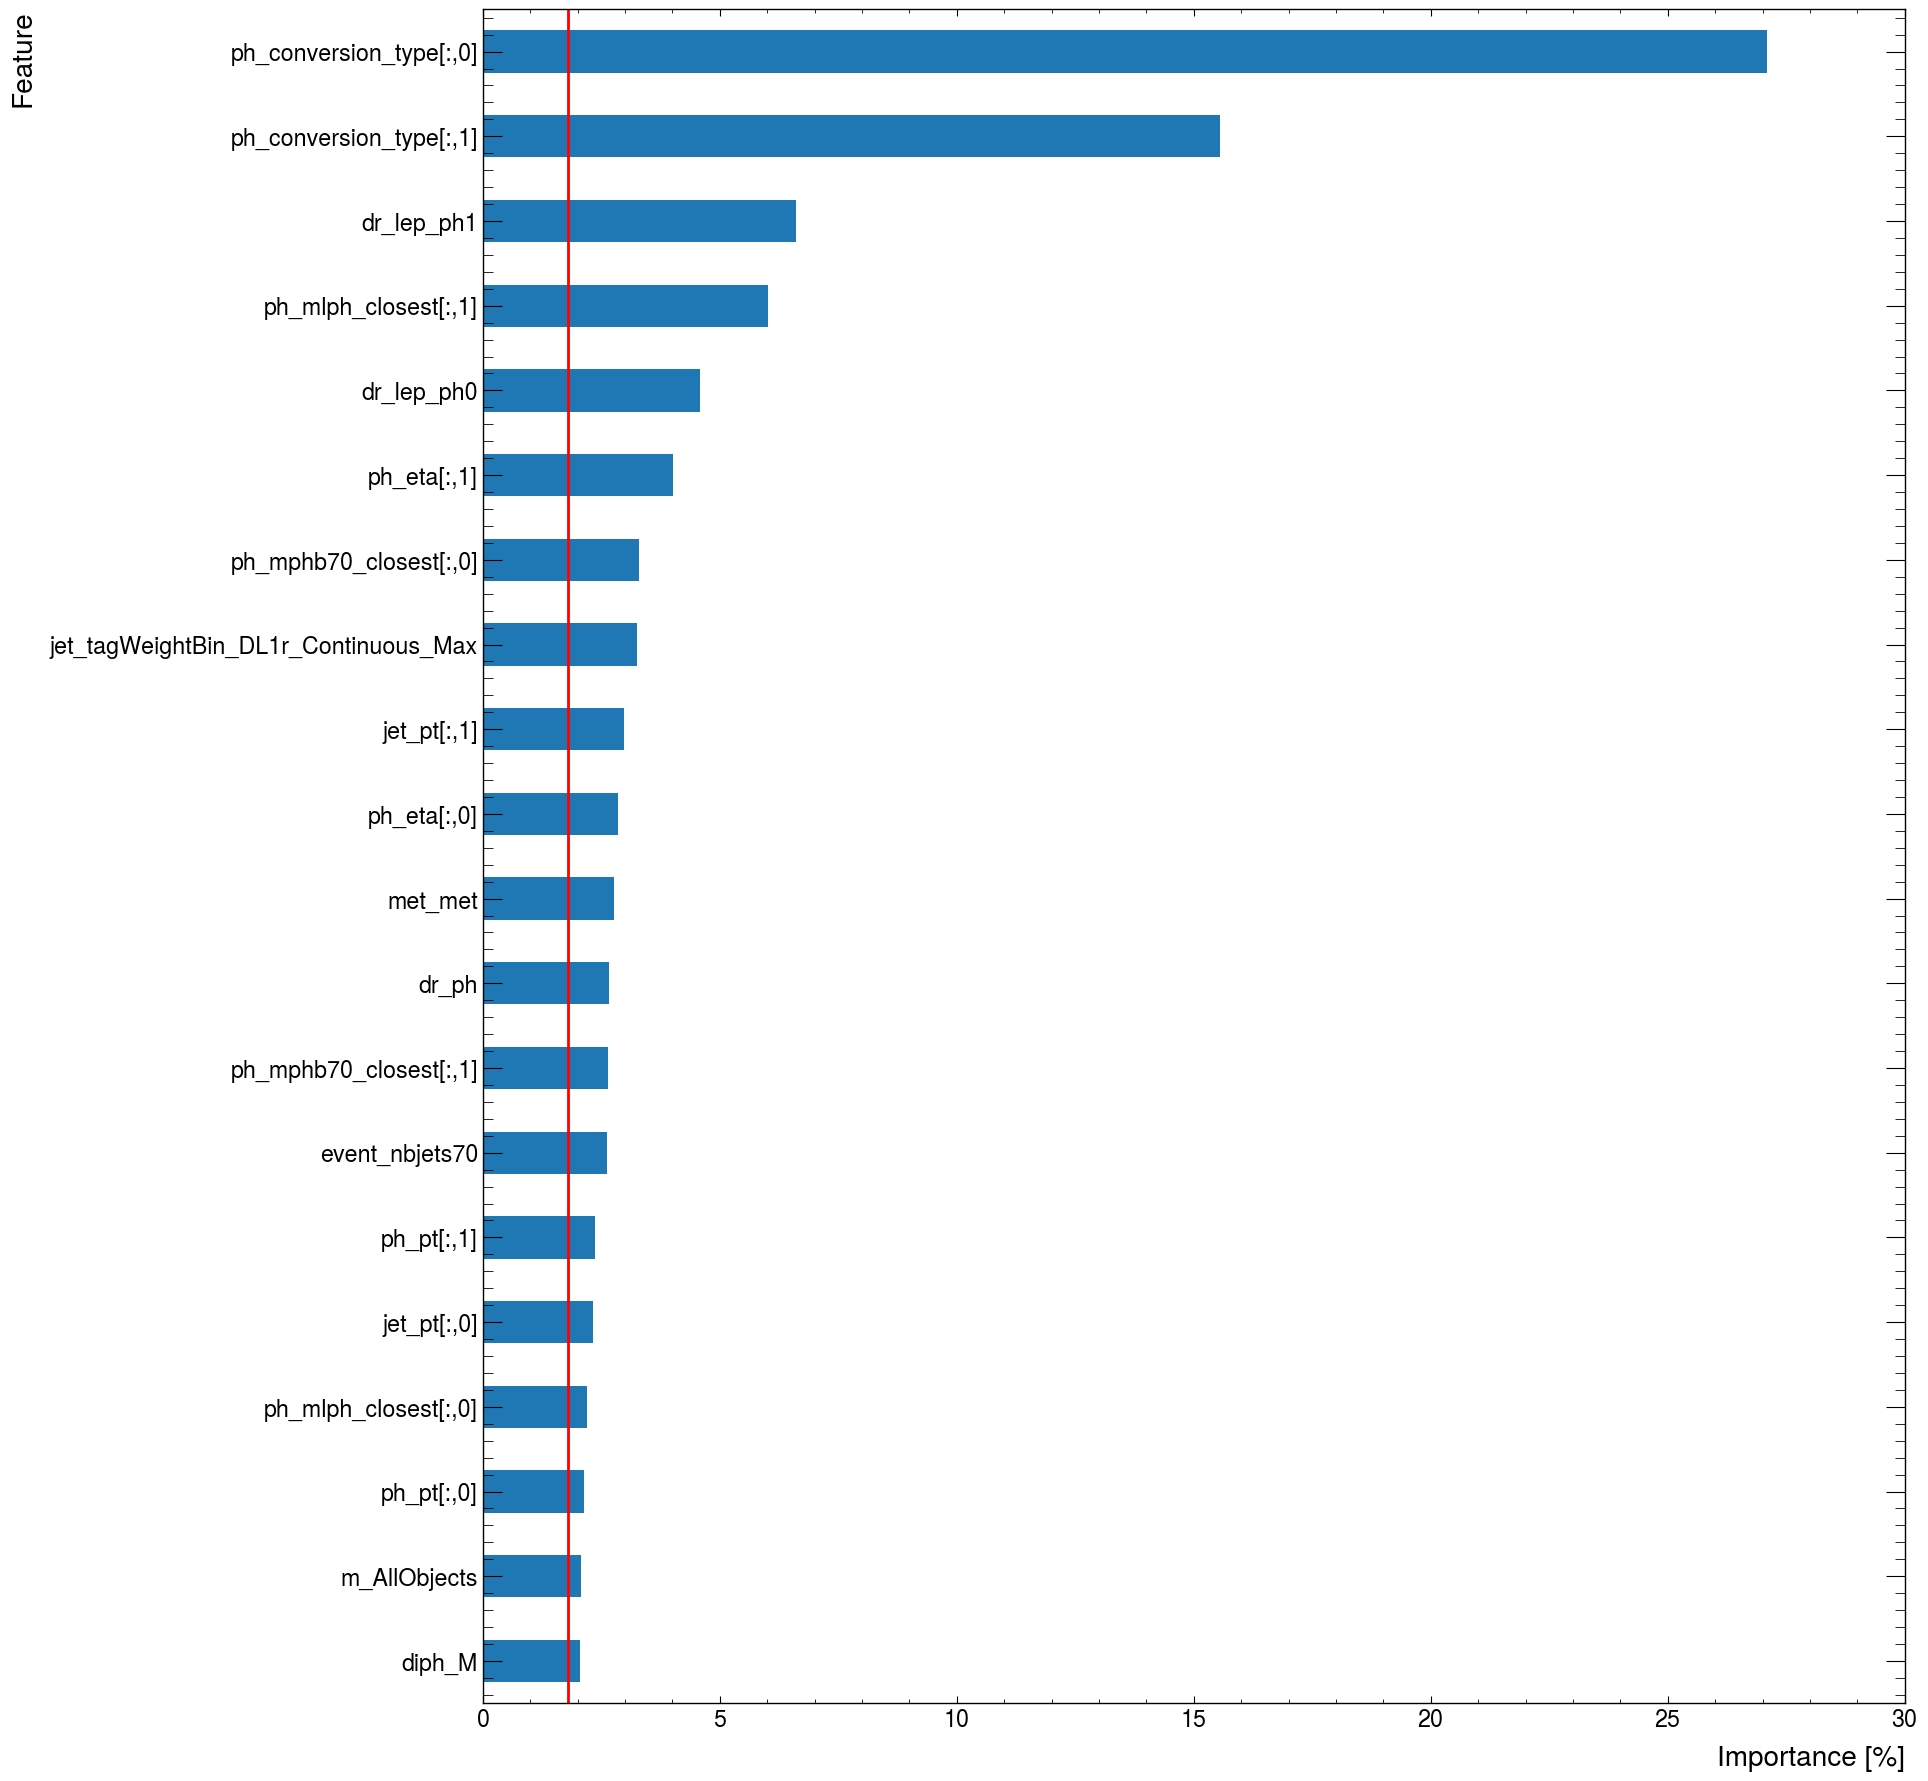

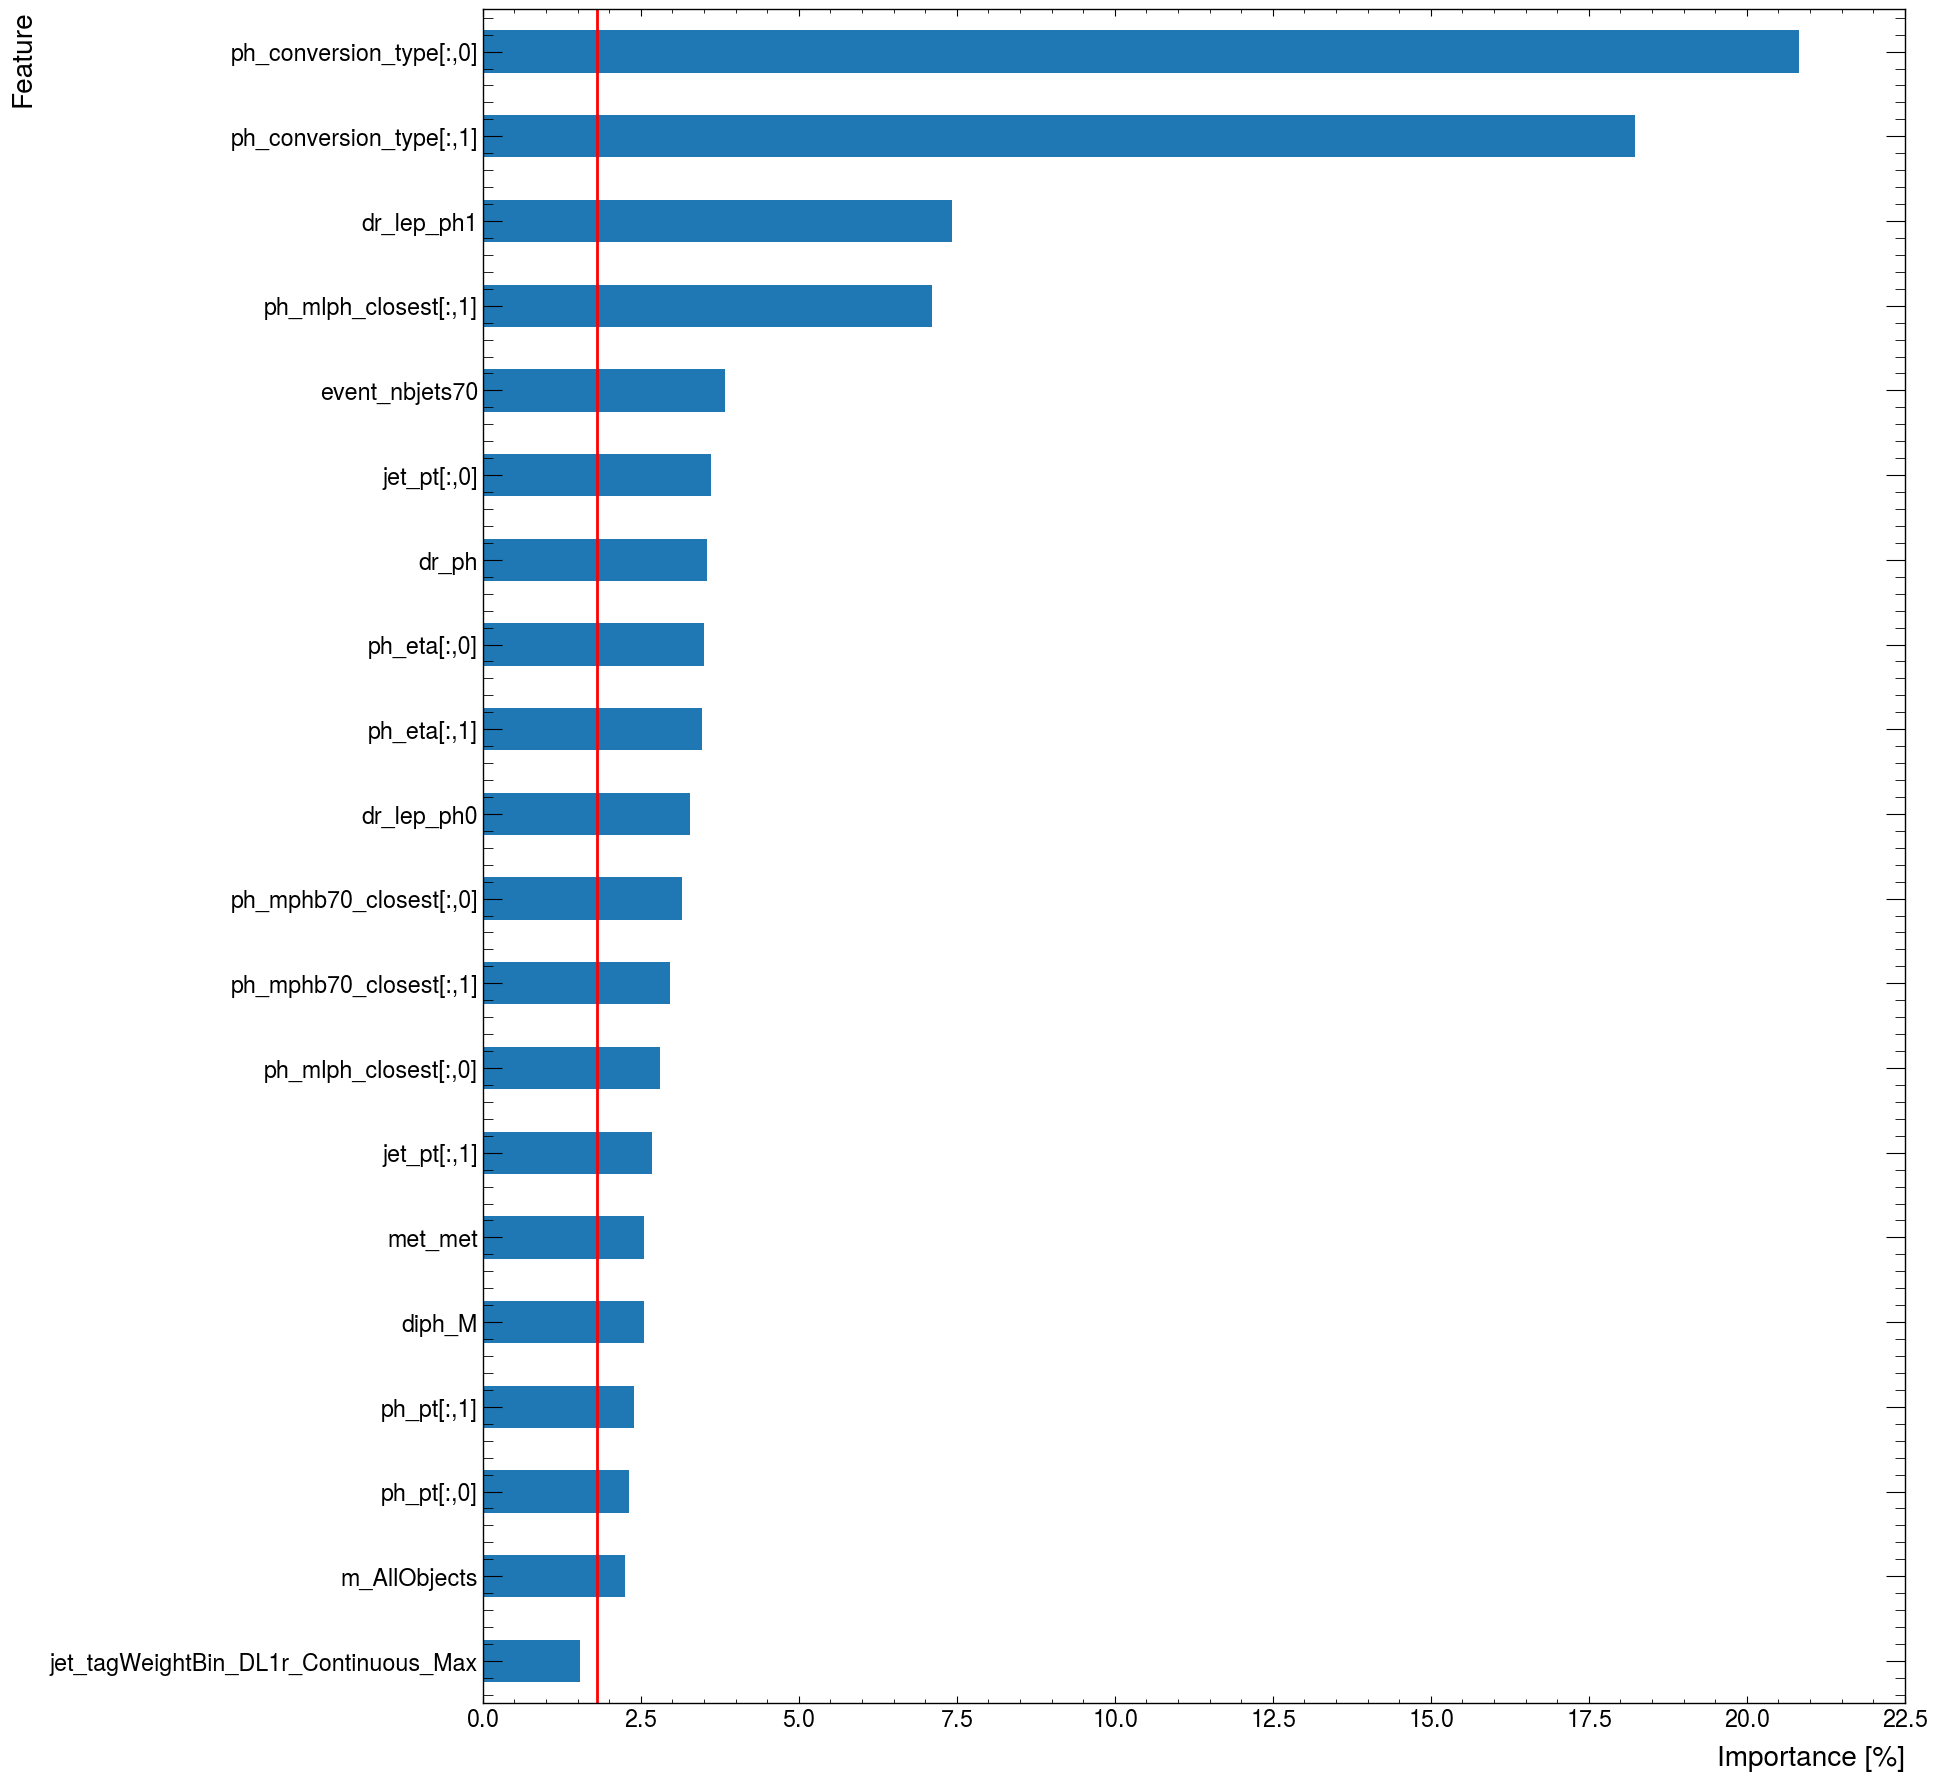

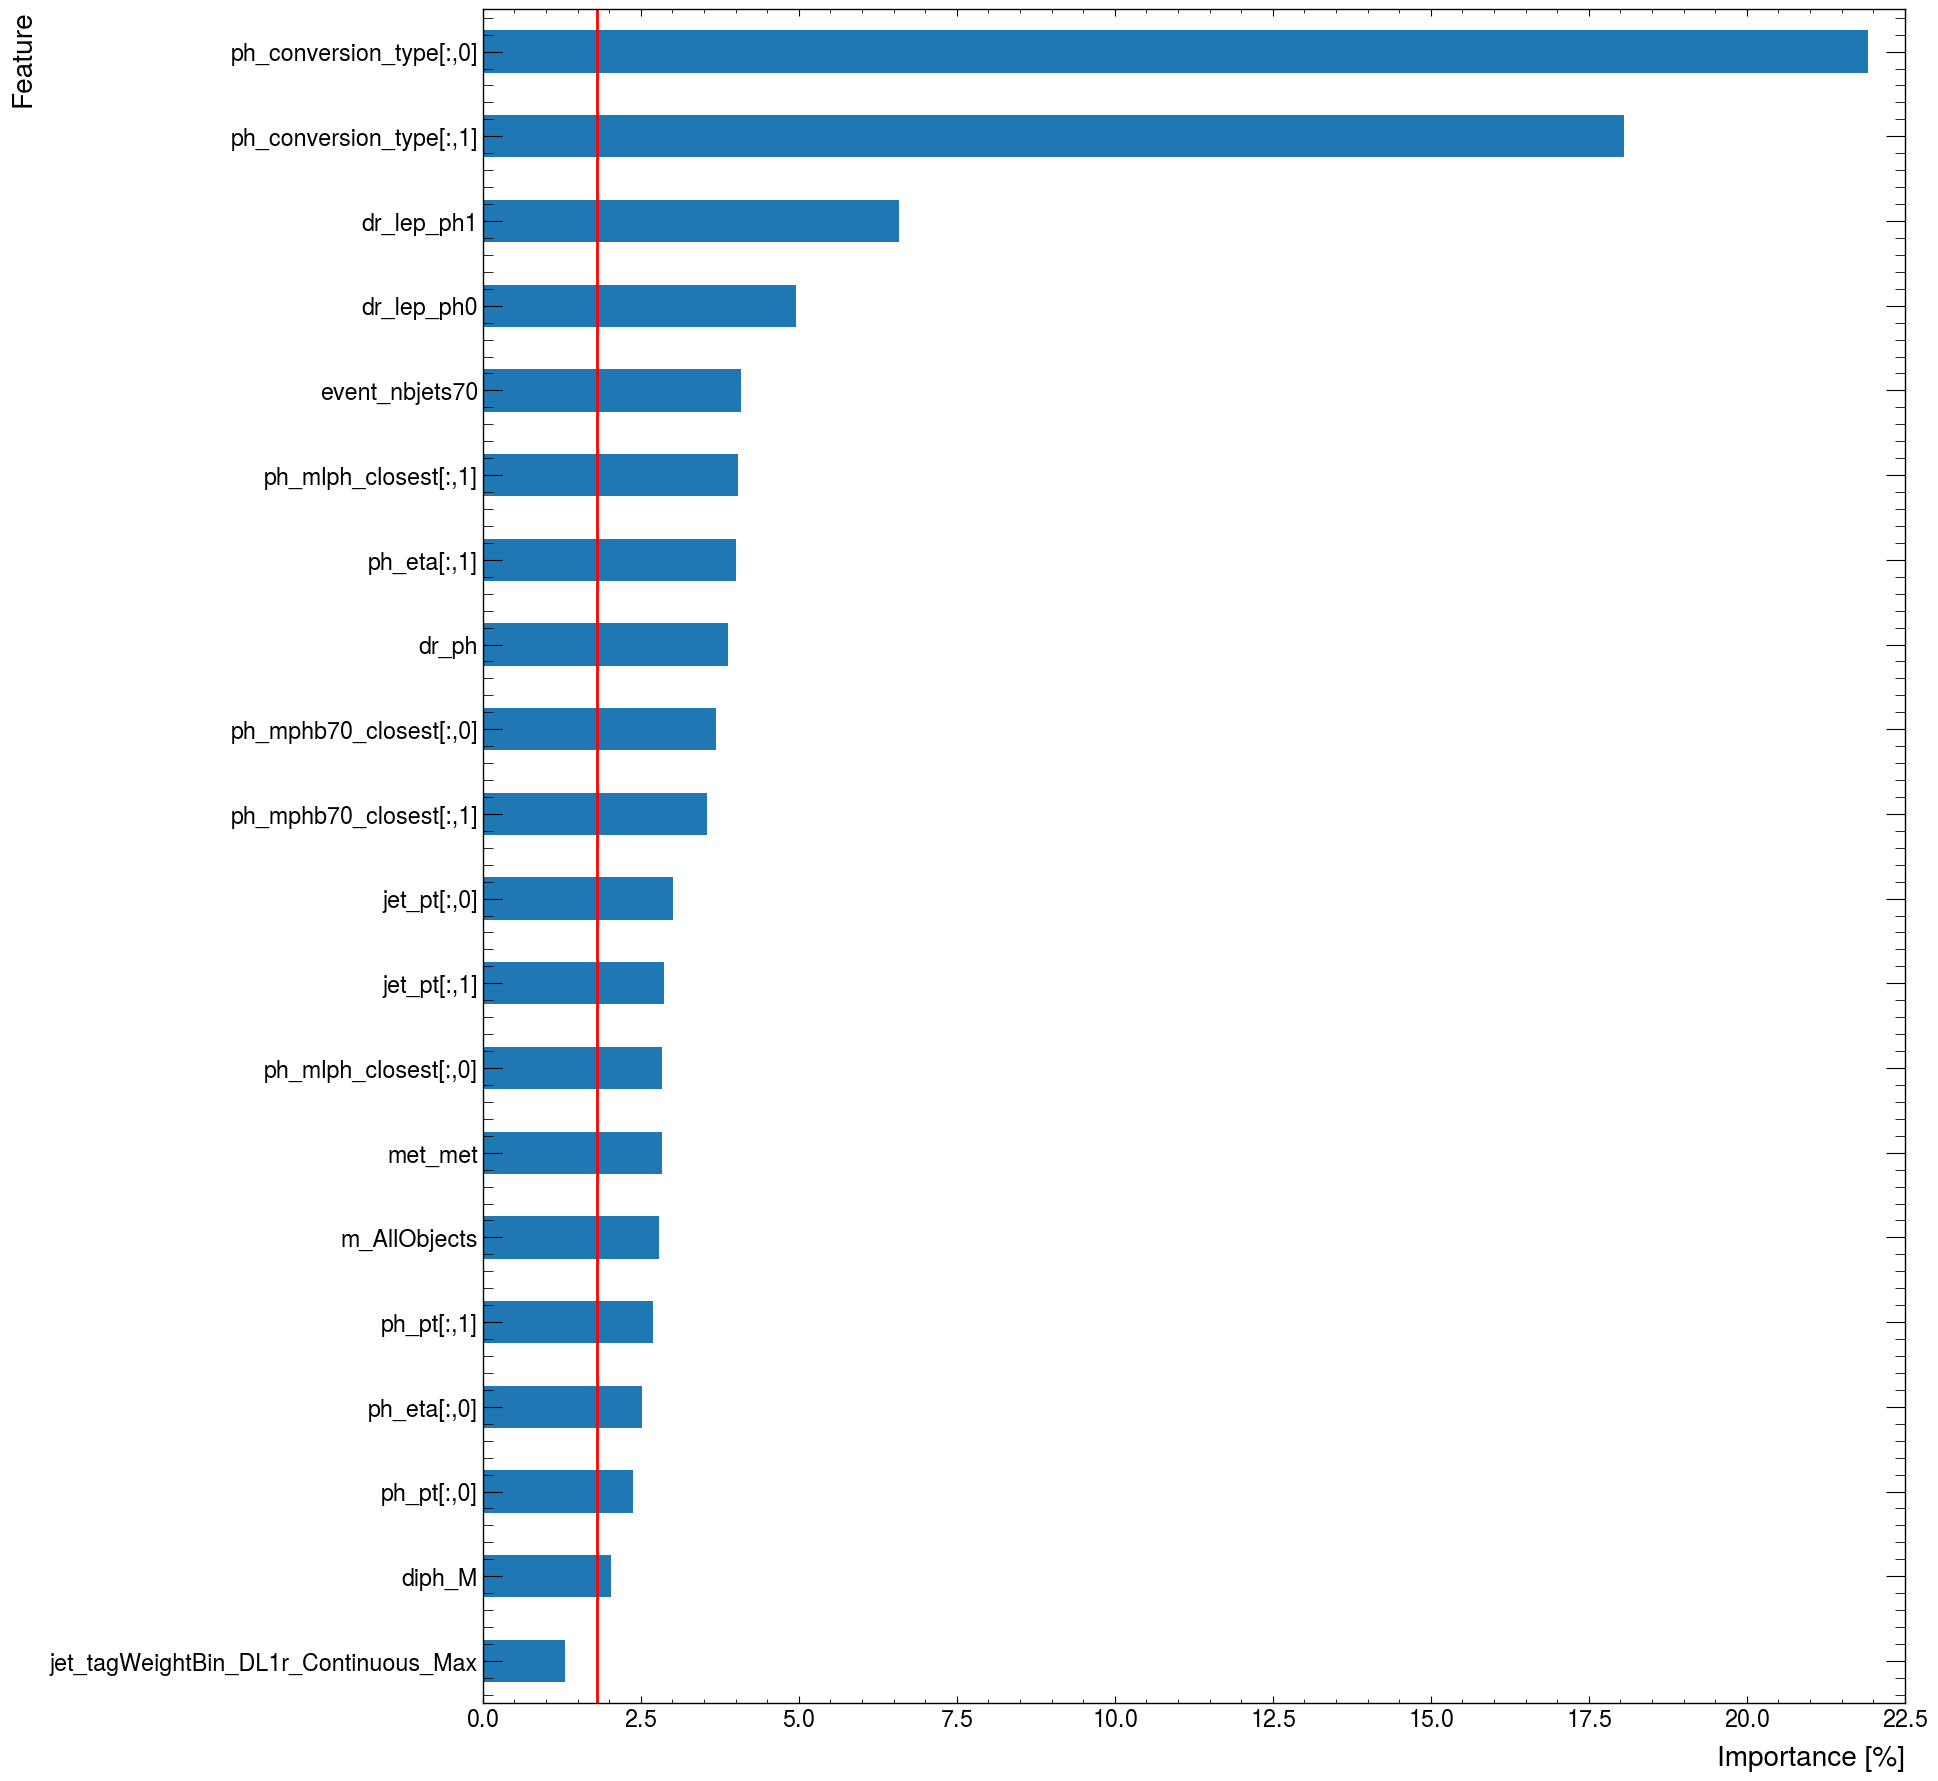

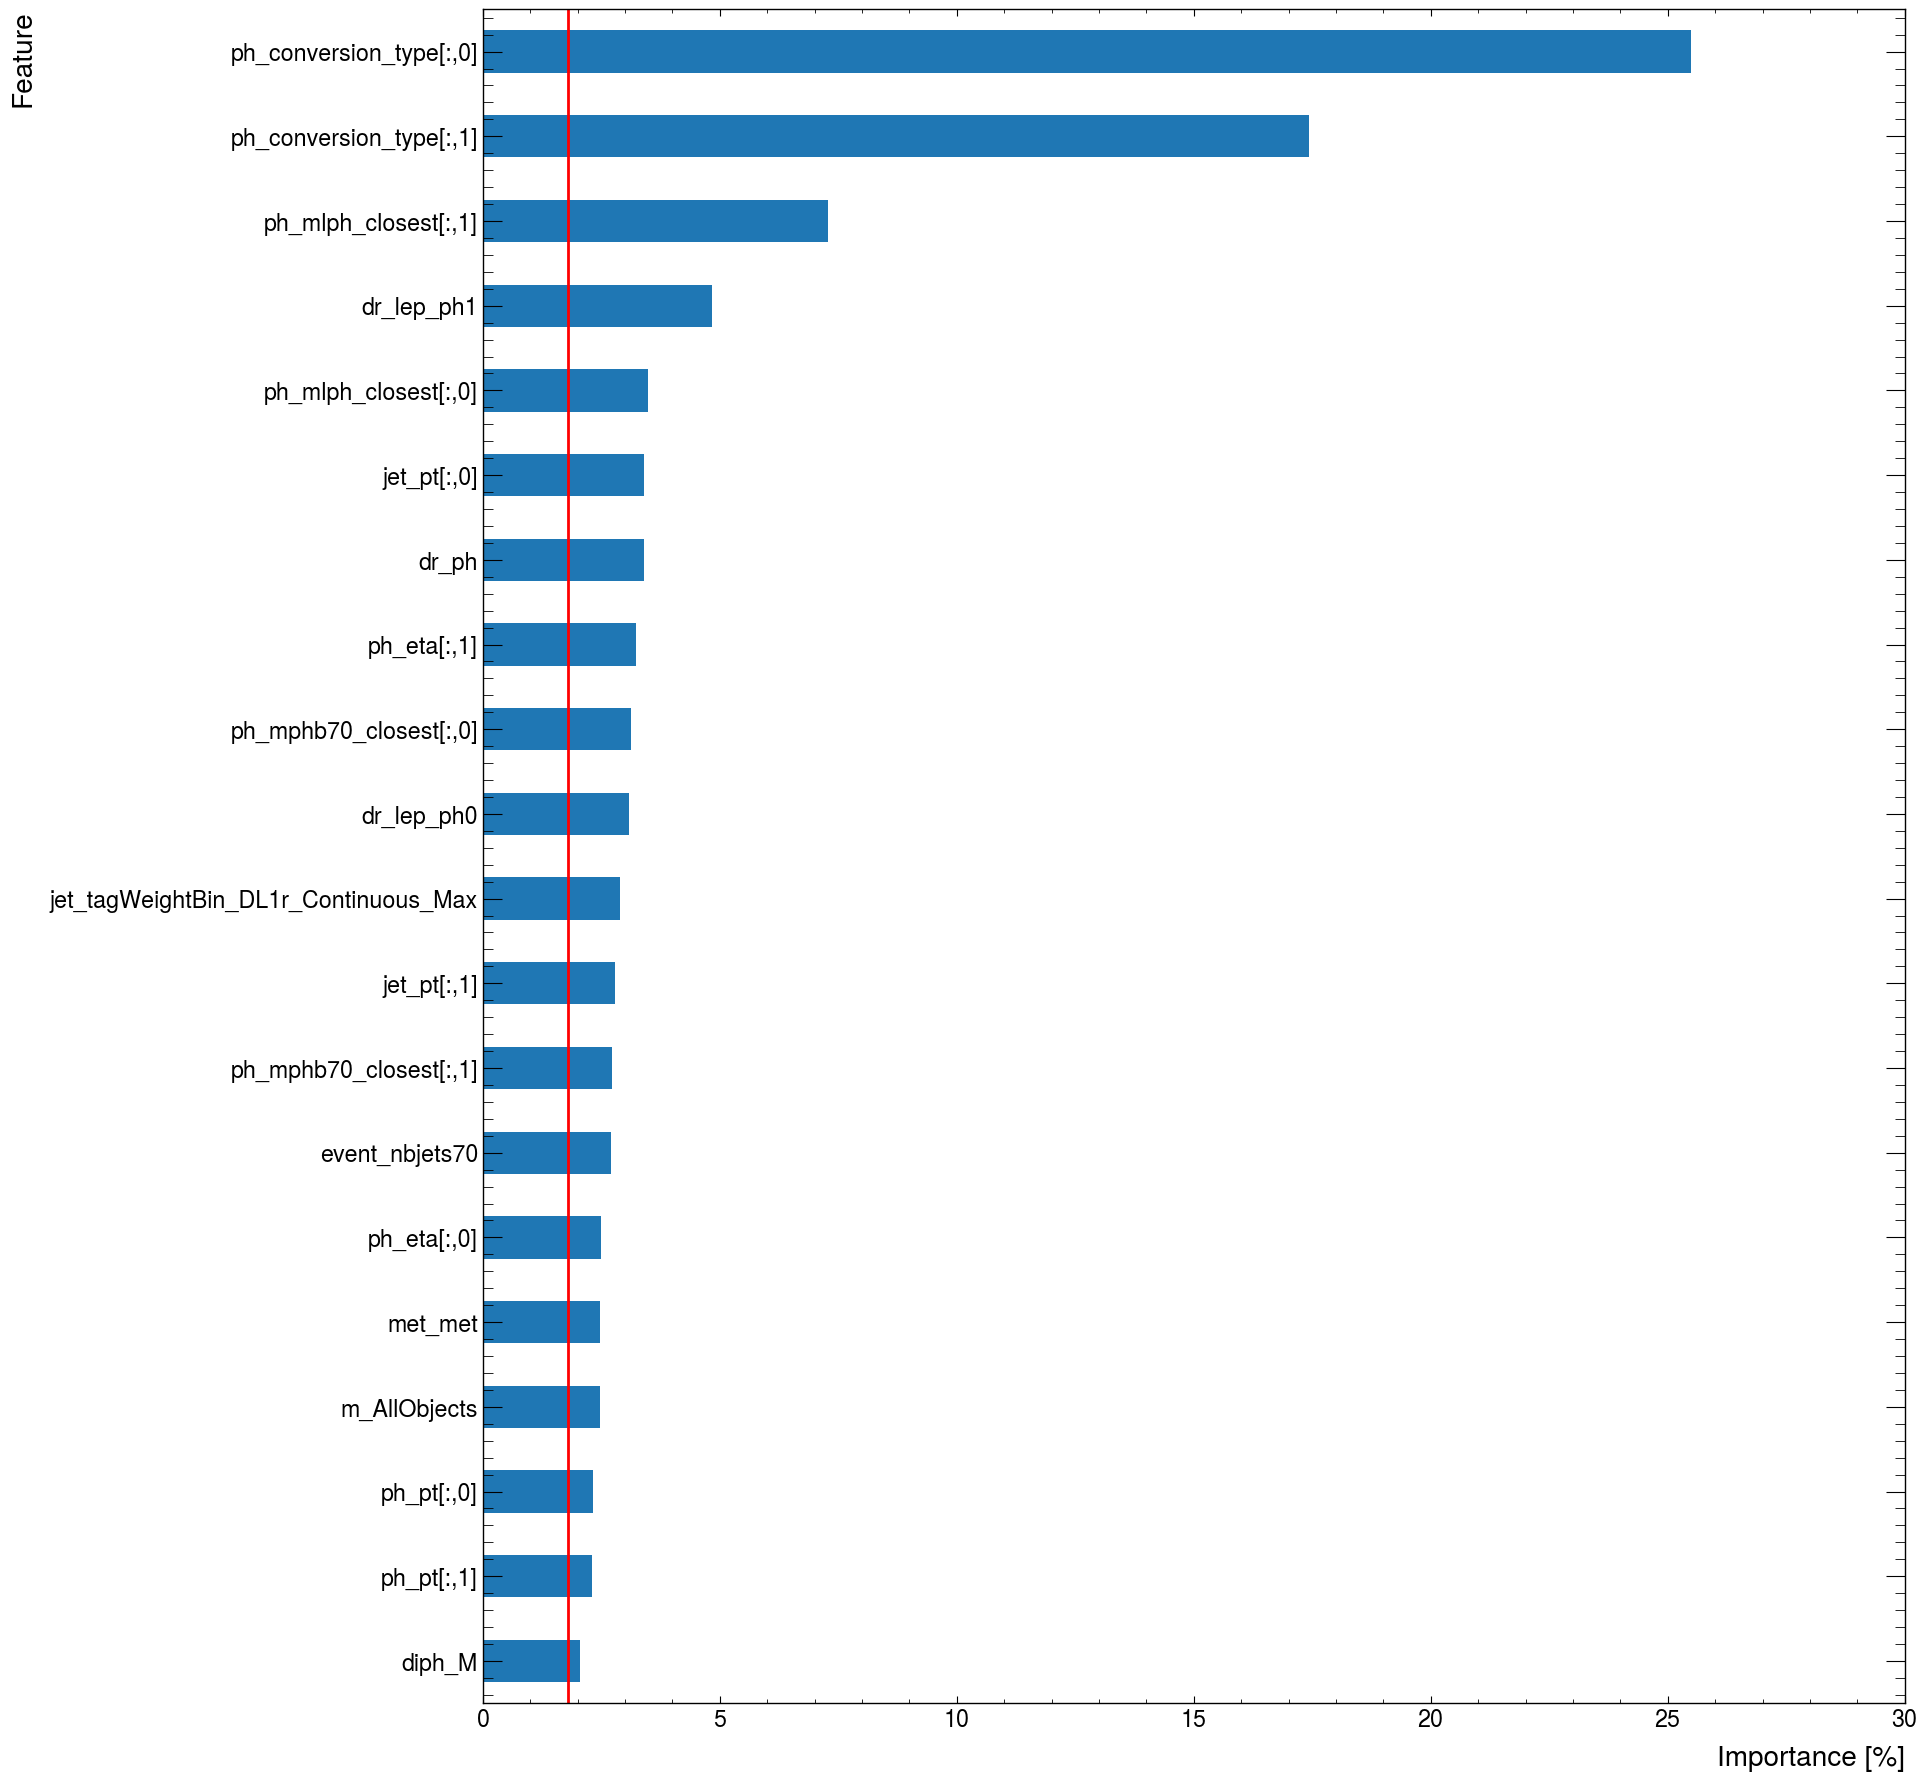

In [37]:
for fold in range(4):
    feature_importances = models[fold].feature_importances_
    feature_imp_list = zip(feature_cols, feature_importances)

    sorted_features = sorted(feature_imp_list, key=lambda x: x[1])
    df = pd.DataFrame(sorted_features, columns = ['Feature','Importance'])
    df['Importance'] = df['Importance'] * 100
    df.set_index('Feature').plot.barh(legend=False, figsize=(18,22))
    plt.xlabel('Importance [%]')
    plt.axvline(1.8,color='red')
   

In [26]:
# Define the custom formatter function
def custom_formatter(x, pos):
    return f'{x * 0.1:.1f}'

-----------------------------------------------
0.005032221013390708 1.919779404681463
0.005519536961499228 1.8754722039899063
11 10 10
Signal train histogram: [0.00503222 0.23725671 0.78106863 1.25727035 1.594384   1.8587518
 1.9197794  1.59999118 0.70817425 0.03829146]
Signal test histogram: [0.00551954 0.2195419  0.75032195 1.25093464 1.56612007 1.81633221
 1.8754722  1.60683772 0.85486719 0.05405213]
Background train histogram: [0.0369382  0.78929252 1.61554299 1.86490612 1.84646167 1.60886924
 1.35163077 0.68206922 0.20084137 0.00344805]
Background test histogram: [0.09723606 0.82970188 1.60469354 1.62322133 2.00811343 1.33575914
 1.50451175 0.72618374 0.27057901 0.1       ]
-----------------------------------------------

Signal train errors: [0.00146232 0.01002918 0.0181896  0.02305173 0.02598022 0.02802661
 0.02847928 0.02587675 0.01717112 0.00398309]
Signal test errors: [0.00085125 0.00558399 0.01030901 0.01333556 0.01490659 0.01600793
 0.01623895 0.0149904  0.01087793 0.00272

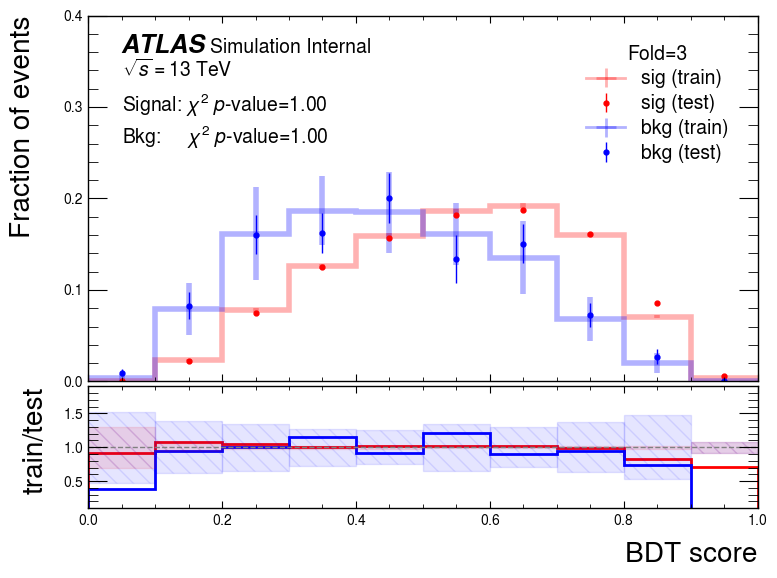

In [43]:
# Working code - Per fold. Change no. of folds
# Unweighted  - with corrected Sumw2()
# Normalized with auc
folds = 4
fold = 3
fig, axes = plt.subplots(nrows=2,ncols=1,gridspec_kw={'height_ratios': [3, 1]}, sharex=True)


# Example dummy data and plots:
results_sig_fold_test = results_sig[df_sig['eventNumber']%folds == fold]
results_bkg_fold_test = results_bkg[df_bkg['eventNumber']%folds == fold]
weights_sig_fold_test = df_sig['weight'][df_sig['eventNumber']%folds == fold]
weights_bkg_fold_test = df_bkg['weight'][df_bkg['eventNumber']%folds == fold]
y = np.concatenate([np.ones_like(results_sig_fold_test), np.zeros_like(results_bkg_fold_test)])
scores = np.concatenate([results_sig_fold_test, results_bkg_fold_test])
weights = np.concatenate([weights_sig_fold_test,weights_bkg_fold_test])

results_sig_fold_train = results_sig[df_sig['eventNumber']%folds != fold]
results_bkg_fold_train = results_bkg[df_bkg['eventNumber']%folds != fold]
weights_sig_fold_train = df_sig['weight'][df_sig['eventNumber']%folds != fold]
weights_bkg_fold_train = df_bkg['weight'][df_bkg['eventNumber']%folds != fold]
y = np.concatenate([np.ones_like(results_sig_fold_train), np.zeros_like(results_bkg_fold_train)])
scores = np.concatenate([results_sig_fold_train, results_bkg_fold_train])
weights = np.concatenate([weights_sig_fold_train,weights_bkg_fold_train])

"""
bc, bb = np.histogram(data1, weights=weights1, range=(-3,3), bins=10)
sumW2, bb = np.histogram(data1, weights=weights1**2, range=(-3,3), bins=10)
mplhep.histplot(bc,bb,yerr=np.sqrt(sumW2),density=True,label='10000 events, weight=0.1', histtype='errorbar')
"""
#bc_sig_train, bb = np.histogram(results_sig_fold_train, weights=weights_sig_fold_train, bins=np.linspace(0,1,11), density=True)


bc_sig_train, bb = np.histogram(results_sig_fold_train, weights=weights_sig_fold_train, range=(0,1), bins=10, density=True)
total_sig_train = len(results_sig_fold_train) #np.sum(bc_sig_train)
sumW2, bb = np.histogram(results_sig_fold_train, weights=weights_sig_fold_train**2, range=(0,1), bins=10)
mplhep.histplot(bc_sig_train,bb,yerr=np.sqrt(sumW2), density=True, label='sig (train)', histtype='step', ax=axes[0], color='red', alpha=0.3, linewidth=4)
bc_sig_train_e = np.sqrt(sumW2)

bc_sig_test, bb = np.histogram(results_sig_fold_test,  weights=weights_sig_fold_test, range=(0,1), bins=10, density=True)
total_sig_test = len(results_sig_fold_test) #np.sum(bc_sig_test)
sumW2, bb = np.histogram(results_sig_fold_test, weights=weights_sig_fold_test**2, range=(0,1), bins=10)
mplhep.histplot(bc_sig_test,bb,yerr=np.sqrt(sumW2),density=True, label='sig (test)', histtype='errorbar', ax=axes[0], color='red', markersize=7)
bc_sig_test_e = np.sqrt(sumW2)

bc_bkg_train, bb = np.histogram(results_bkg_fold_train, weights=weights_bkg_fold_train, range=(0,1), bins=10, density=True)
total_bkg_train = len(results_bkg_fold_train) #np.sum(bc_sig_train)
sumW2, bb = np.histogram(results_bkg_fold_train, weights=weights_bkg_fold_train**2, range=(0,1), bins=10)
mplhep.histplot(bc_bkg_train,bb,yerr=np.sqrt(sumW2), density=True, label='bkg (train)', histtype='step', ax=axes[0], color='blue', alpha=0.3, linewidth=4)
bc_bkg_train_e = np.sqrt(sumW2)


bc_bkg_test, bb = np.histogram(results_bkg_fold_test,  weights=weights_bkg_fold_test, range=(0,1), bins=10, density=True)
total_bkg_test = len(results_bkg_fold_test) #np.sum(bc_sig_test)
sumW2, bb = np.histogram(results_bkg_fold_test, weights=weights_bkg_fold_test**2, range=(0,1), bins=10)
mplhep.histplot(bc_bkg_test,bb,yerr=np.sqrt(sumW2), density=True, label='bkg (test)', histtype='errorbar', ax=axes[0], color='blue', markersize=7)
bc_bkg_test_e = np.sqrt(sumW2)




print("-----------------------------------------------")
# Example check if data is within expected range
print(bc_sig_train.min(), bc_sig_train.max())
print(bc_sig_test.min(), bc_sig_test.max())

print(len(bb), len(bc_sig_train), len(bc_bkg_train))
bc_bkg_test = np.where(bc_bkg_test == 0, 1e-1, bc_bkg_test)


corr_factor_sig = np.sum(bc_sig_train)/np.sum(bc_sig_test)
chi2_sig, p_sig = chisquare(bc_sig_train, bc_sig_test*corr_factor_sig)
corr_factor_bkg = np.sum(bc_bkg_train)/np.sum(bc_bkg_test)
chi2_bkg, p_bkg = chisquare(bc_bkg_train, bc_bkg_test*corr_factor_bkg)


axes[0].set_xlim(0,1)
axes[0].set_ylim(0,4)

#scale_and_format_y_axis(axes[0], scale_factor=0.1)  # Adjust scale_factor as needed

# Create the FuncFormatter object
formatter = mtick.FuncFormatter(custom_formatter)

# Apply the custom formatter to the y-axis
axes[0].yaxis.set_major_formatter(formatter)
axes[0].yaxis.set_major_locator(mtick.MultipleLocator(1))   # removing this will lead to duplicate labels


axes[0].legend(title=F'Fold={fold}', loc='upper right')

#ax.set_xlabel('BDT score')
axes[0].set_ylabel('Fraction of events', labelpad=20)
mplhep.atlas.label('Internal', data=False, ax=axes[0])
axes[0].text(x=0.05, y=2.6,s=F'Signal: $\chi^2$ $p$-value={p_sig:.2f}\nBkg:     $\chi^2$ $p$-value={p_bkg:.2f}')
axes[0].tick_params(axis='both', labelsize=10)

print("Signal train histogram:", bc_sig_train)
print("Signal test histogram:", bc_sig_test)
print("Background train histogram:", bc_bkg_train)
print("Background test histogram:", bc_bkg_test)

print("-----------------------------------------------")




#y1 = bc_sig_train
#y1err = np.sqrt(sumW2) # calculated from sig train
#y2 = bc_sig_test
#y2err = np.sqrt(sumW2) # calculated from sig test






# Errors on histograms:
#bc_sig_train_e = np.sqrt(bc_sig_train/total_sig_train)*10  #np.sqrt(bc_sig_train)
#bc_sig_test_e = np.sqrt(bc_sig_test/total_sig_test)*10  #np.sqrt(bc_sig_test)
#bc_bkg_train_e = np.sqrt(bc_bkg_train/total_bkg_train)*10  #np.sqrt(bc_bkg_train)
#bc_bkg_test_e = np.sqrt(bc_bkg_test/total_bkg_test)*10  #np.sqrt(bc_bkg_test)





print("\nSignal train errors:", bc_sig_train_e)
print("Signal test errors:", bc_sig_test_e)
print("Background train errors:", bc_bkg_train_e)
print("Background test errors:", bc_bkg_test_e)

print("-----------------------------------------------")

ratio_sig = np.where(bc_sig_test == 0, 1, bc_sig_train / bc_sig_test)
ratio_bkg = np.where(bc_bkg_test == 0, 1, bc_bkg_train / bc_bkg_test)


print("\nSig ratio: ", ratio_sig)
print("Bkg ratio: ", ratio_bkg)


ratio_sig_e = np.sqrt((bc_sig_train/(1.0*bc_sig_test*bc_sig_test))*(bc_sig_train/(1.0*bc_sig_test*bc_sig_test))*bc_sig_test_e*bc_sig_test_e+(1/(1.0*bc_sig_test))*(1/(1.0*bc_sig_test))*bc_sig_train_e*bc_sig_train_e)
ratio_bkg_e = np.sqrt((bc_bkg_train/(1.0*bc_bkg_test*bc_bkg_test))*(bc_bkg_train/(1.0*bc_bkg_test*bc_bkg_test))*bc_bkg_test_e*bc_bkg_test_e+(1/(1.0*bc_bkg_test))*(1/(1.0*bc_bkg_test))*bc_bkg_train_e*bc_bkg_train_e)

print("\nSig Ratio uncertainties per bin: ", ratio_sig_e)



# Ratio plot
#ratio_sig = bc_sig_train/bc_sig_test # np.divide(bc_sig_train, bc_sig_test, out=np.zeros_like(bc_sig_train), where=bc_sig_test != 0)
#ratio_bkg = bc_bkg_train/bc_bkg_test #  np.divide(bc_bkg_train, bc_bkg_test, out=np.zeros_like(bc_bkg_train), where=bc_bkg_test != 0)
#print(bb)
#print(ratio_sig)
#print(ratio_bkg)
#print(len(bb), len(ratio_sig), len(ratio_bkg))

# Clip errors and add padding
max_error = 100  # Example maximum error threshold
clipped_errors_sig = np.clip(ratio_sig_e, 0, max_error)
clipped_errors_bkg = np.clip(ratio_bkg_e, 0, max_error)

print("Clipped errors:", clipped_errors_sig)
print("Clipped errors:", clipped_errors_bkg)




bb_centers = (bb[:-1] + bb[1:]) / 2
#axes[1].plot(bb_centers, ratio_sig, 'o', label='Sig', color='red', linestyle='None', markersize=5)
#axes[1].plot(bb_centers, ratio_bkg, 'o', label='Bkg', color='blue', linestyle='None', markersize=5)
#axes[1].axhline(1,0,1,linestyle='--',color='grey')

mplhep.histplot(ratio_sig, bb, histtype='step', ax=axes[1], color='red', linewidth=2)
mplhep.histplot(ratio_bkg, bb, histtype='step', ax=axes[1], color='blue', linewidth=2)


# Plot with clipped errors
#axes[1].fill_between(bb_centers, y1=(ratio_sig + clipped_errors_sig), y2=(ratio_sig - clipped_errors_sig), alpha=0.2, color='red')
#axes[1].fill_between(bb_centers, y1=(ratio_bkg + clipped_errors_bkg), y2=(ratio_bkg - clipped_errors_bkg), alpha=0.2, color='blue')

#axes[1].fill_between(bb_centers, y1=(1 + clipped_errors_sig), y2=(1 - clipped_errors_sig), alpha=0.2, color='red', hatch='\\\\', zorder=1) 
#axes[1].fill_between(bb_centers, y1=(1 + clipped_errors_bkg), y2=(1 - clipped_errors_bkg), alpha=0.2, color='blue', hatch='/', zorder=1) 


# Plot the ratio uncertainty bands with hatch styles
#axes[1].fill_between(
#    bb_centers, y1=(1 + clipped_errors_sig), y2=(1 - clipped_errors_sig), facecolor='none', edgecolor='red', hatch='\\\\', zorder=1, linewidth=0.0)
#axes[1].fill_between(
#    bb_centers, y1=(1 + clipped_errors_bkg), y2=(1 - clipped_errors_bkg), facecolor='none', edgecolor='#CCCCFF', hatch='///', zorder=1, linewidth=0.0)


#axes[1].fill_between(
#    bb_centers, y1=(1 + clipped_errors_sig), y2=(1 - clipped_errors_sig), facecolor='red', alpha=0.2, edgecolor='red', hatch='\\\\', zorder=1)

bin_width = bb[1] - bb[0] 
# Plot the uncertainty band in histogram style using bar
for center, err in zip(bb_centers, clipped_errors_sig):
    axes[1].bar(center, 2 * err, width=bin_width, bottom=1 - err, color='red', alpha=0.1, edgecolor='red', hatch='\\\\', align='center')
for center, err in zip(bb_centers, clipped_errors_bkg):
    axes[1].bar(center, 2 * err, width=bin_width, bottom=1 - err, color='blue', alpha=0.1, edgecolor='blue', hatch='\\\\', align='center')


#axes[1].set_dashes((5,2))

axes[1].axhline(1,0,1,linestyle='--',color='grey', linewidth=1)
axes[1].set_ylabel('train/test')
axes[1].set_xlabel('BDT score')
axes[1].tick_params(axis='both', labelsize=10)

axes[1].set_ylim(0.1,1.9)  # Adjust based on your ratio values
fig.tight_layout()
fig.subplots_adjust(hspace=0.02)
fig.savefig(f'Test_Train_Chi_Squared_Unweighted_{fold}_Model6_10bins_19vars.png')

-----------------------------------------------
0.005379851665305511 1.909546600248946
0.004475741891343253 1.906081738930576
11 10 10
Signal train histogram: [0.00537985 0.23601135 0.76173408 1.24727044 1.5786057  1.83626908
 1.9095466  1.61806662 0.76385876 0.04325762]
Signal test histogram: [0.00447574 0.22321912 0.80836163 1.28099026 1.61347211 1.88379666
 1.90608174 1.55249237 0.687936   0.03917501]
Background train histogram: [0.05885087 0.75553709 1.63712151 1.6418503  1.88029836 1.58302763
 1.46019926 0.72809339 0.25170392 0.00331706]
Background test histogram: [0.02901654 0.95239614 1.5282383  2.36679576 1.91182416 1.38952989
 1.14724459 0.57199834 0.10295643 0.1       ]
-----------------------------------------------

Signal train errors: [0.00147496 0.0100203  0.01798738 0.02299682 0.02590668 0.02786792
 0.02840388 0.02605057 0.01782708 0.00422843]
Signal test errors: [0.00082916 0.00559992 0.01065793 0.01343003 0.01503402 0.01628261
 0.01637048 0.01468626 0.00976584 0.00232

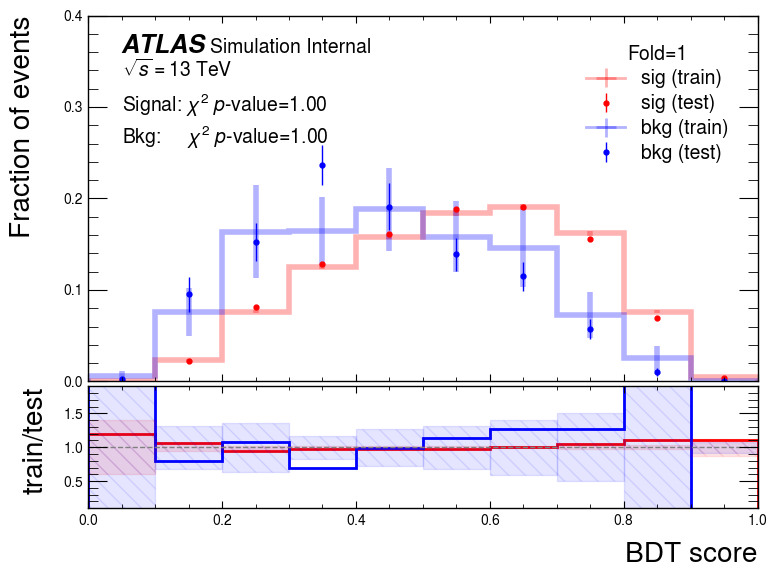

In [35]:
# Working code - Per fold. Change no. of folds
# Unweighted  - with corrected Sumw2()
# Normalized with auc
folds = 4
fold = 1
fig, axes = plt.subplots(nrows=2,ncols=1,gridspec_kw={'height_ratios': [3, 1]}, sharex=True)


# Example dummy data and plots:
results_sig_fold_test = results_sig[df_sig['eventNumber']%folds == fold]
results_bkg_fold_test = results_bkg[df_bkg['eventNumber']%folds == fold]
weights_sig_fold_test = df_sig['weight'][df_sig['eventNumber']%folds == fold]
weights_bkg_fold_test = df_bkg['weight'][df_bkg['eventNumber']%folds == fold]
y = np.concatenate([np.ones_like(results_sig_fold_test), np.zeros_like(results_bkg_fold_test)])
scores = np.concatenate([results_sig_fold_test, results_bkg_fold_test])
weights = np.concatenate([weights_sig_fold_test,weights_bkg_fold_test])

results_sig_fold_train = results_sig[df_sig['eventNumber']%folds != fold]
results_bkg_fold_train = results_bkg[df_bkg['eventNumber']%folds != fold]
weights_sig_fold_train = df_sig['weight'][df_sig['eventNumber']%folds != fold]
weights_bkg_fold_train = df_bkg['weight'][df_bkg['eventNumber']%folds != fold]
y = np.concatenate([np.ones_like(results_sig_fold_train), np.zeros_like(results_bkg_fold_train)])
scores = np.concatenate([results_sig_fold_train, results_bkg_fold_train])
weights = np.concatenate([weights_sig_fold_train,weights_bkg_fold_train])

"""
bc, bb = np.histogram(data1, weights=weights1, range=(-3,3), bins=10)
sumW2, bb = np.histogram(data1, weights=weights1**2, range=(-3,3), bins=10)
mplhep.histplot(bc,bb,yerr=np.sqrt(sumW2),density=True,label='10000 events, weight=0.1', histtype='errorbar')
"""
#bc_sig_train, bb = np.histogram(results_sig_fold_train, weights=weights_sig_fold_train, bins=np.linspace(0,1,11), density=True)


bc_sig_train, bb = np.histogram(results_sig_fold_train, weights=weights_sig_fold_train, range=(0,1), bins=10, density=True)
total_sig_train = len(results_sig_fold_train) #np.sum(bc_sig_train)
sumW2, bb = np.histogram(results_sig_fold_train, weights=weights_sig_fold_train**2, range=(0,1), bins=10)
mplhep.histplot(bc_sig_train,bb,yerr=np.sqrt(sumW2), density=True, label='sig (train)', histtype='step', ax=axes[0], color='red', alpha=0.3, linewidth=4)
bc_sig_train_e = np.sqrt(sumW2)

bc_sig_test, bb = np.histogram(results_sig_fold_test,  weights=weights_sig_fold_test, range=(0,1), bins=10, density=True)
total_sig_test = len(results_sig_fold_test) #np.sum(bc_sig_test)
sumW2, bb = np.histogram(results_sig_fold_test, weights=weights_sig_fold_test**2, range=(0,1), bins=10)
mplhep.histplot(bc_sig_test,bb,yerr=np.sqrt(sumW2),density=True, label='sig (test)', histtype='errorbar', ax=axes[0], color='red', markersize=7)
bc_sig_test_e = np.sqrt(sumW2)

bc_bkg_train, bb = np.histogram(results_bkg_fold_train, weights=weights_bkg_fold_train, range=(0,1), bins=10, density=True)
total_bkg_train = len(results_bkg_fold_train) #np.sum(bc_sig_train)
sumW2, bb = np.histogram(results_bkg_fold_train, weights=weights_bkg_fold_train**2, range=(0,1), bins=10)
mplhep.histplot(bc_bkg_train,bb,yerr=np.sqrt(sumW2), density=True, label='bkg (train)', histtype='step', ax=axes[0], color='blue', alpha=0.3, linewidth=4)
bc_bkg_train_e = np.sqrt(sumW2)


bc_bkg_test, bb = np.histogram(results_bkg_fold_test,  weights=weights_bkg_fold_test, range=(0,1), bins=10, density=True)
total_bkg_test = len(results_bkg_fold_test) #np.sum(bc_sig_test)
sumW2, bb = np.histogram(results_bkg_fold_test, weights=weights_bkg_fold_test**2, range=(0,1), bins=10)
mplhep.histplot(bc_bkg_test,bb,yerr=np.sqrt(sumW2), density=True, label='bkg (test)', histtype='errorbar', ax=axes[0], color='blue', markersize=7)
bc_bkg_test_e = np.sqrt(sumW2)




print("-----------------------------------------------")
# Example check if data is within expected range
print(bc_sig_train.min(), bc_sig_train.max())
print(bc_sig_test.min(), bc_sig_test.max())

print(len(bb), len(bc_sig_train), len(bc_bkg_train))
bc_bkg_test = np.where(bc_bkg_test == 0, 1e-1, bc_bkg_test)


corr_factor_sig = np.sum(bc_sig_train)/np.sum(bc_sig_test)
chi2_sig, p_sig = chisquare(bc_sig_train, bc_sig_test*corr_factor_sig)
corr_factor_bkg = np.sum(bc_bkg_train)/np.sum(bc_bkg_test)
chi2_bkg, p_bkg = chisquare(bc_bkg_train, bc_bkg_test*corr_factor_bkg)


axes[0].set_xlim(0,1)
axes[0].set_ylim(0,4)

#scale_and_format_y_axis(axes[0], scale_factor=0.1)  # Adjust scale_factor as needed

# Create the FuncFormatter object
formatter = mtick.FuncFormatter(custom_formatter)

# Apply the custom formatter to the y-axis
axes[0].yaxis.set_major_formatter(formatter)
axes[0].yaxis.set_major_locator(mtick.MultipleLocator(1))   # removing this will lead to duplicate labels


axes[0].legend(title=F'Fold={fold}', loc='upper right')

#ax.set_xlabel('BDT score')
axes[0].set_ylabel('Fraction of events', labelpad=20)
mplhep.atlas.label('Internal', data=False, ax=axes[0])
axes[0].text(x=0.05, y=2.6,s=F'Signal: $\chi^2$ $p$-value={p_sig:.2f}\nBkg:     $\chi^2$ $p$-value={p_bkg:.2f}')
axes[0].tick_params(axis='both', labelsize=10)

print("Signal train histogram:", bc_sig_train)
print("Signal test histogram:", bc_sig_test)
print("Background train histogram:", bc_bkg_train)
print("Background test histogram:", bc_bkg_test)

print("-----------------------------------------------")




#y1 = bc_sig_train
#y1err = np.sqrt(sumW2) # calculated from sig train
#y2 = bc_sig_test
#y2err = np.sqrt(sumW2) # calculated from sig test






# Errors on histograms:
#bc_sig_train_e = np.sqrt(bc_sig_train/total_sig_train)*10  #np.sqrt(bc_sig_train)
#bc_sig_test_e = np.sqrt(bc_sig_test/total_sig_test)*10  #np.sqrt(bc_sig_test)
#bc_bkg_train_e = np.sqrt(bc_bkg_train/total_bkg_train)*10  #np.sqrt(bc_bkg_train)
#bc_bkg_test_e = np.sqrt(bc_bkg_test/total_bkg_test)*10  #np.sqrt(bc_bkg_test)





print("\nSignal train errors:", bc_sig_train_e)
print("Signal test errors:", bc_sig_test_e)
print("Background train errors:", bc_bkg_train_e)
print("Background test errors:", bc_bkg_test_e)

print("-----------------------------------------------")

ratio_sig = np.where(bc_sig_test == 0, 1, bc_sig_train / bc_sig_test)
ratio_bkg = np.where(bc_bkg_test == 0, 1, bc_bkg_train / bc_bkg_test)


print("\nSig ratio: ", ratio_sig)
print("Bkg ratio: ", ratio_bkg)


ratio_sig_e = np.sqrt((bc_sig_train/(1.0*bc_sig_test*bc_sig_test))*(bc_sig_train/(1.0*bc_sig_test*bc_sig_test))*bc_sig_test_e*bc_sig_test_e+(1/(1.0*bc_sig_test))*(1/(1.0*bc_sig_test))*bc_sig_train_e*bc_sig_train_e)
ratio_bkg_e = np.sqrt((bc_bkg_train/(1.0*bc_bkg_test*bc_bkg_test))*(bc_bkg_train/(1.0*bc_bkg_test*bc_bkg_test))*bc_bkg_test_e*bc_bkg_test_e+(1/(1.0*bc_bkg_test))*(1/(1.0*bc_bkg_test))*bc_bkg_train_e*bc_bkg_train_e)

print("\nSig Ratio uncertainties per bin: ", ratio_sig_e)



# Ratio plot
#ratio_sig = bc_sig_train/bc_sig_test # np.divide(bc_sig_train, bc_sig_test, out=np.zeros_like(bc_sig_train), where=bc_sig_test != 0)
#ratio_bkg = bc_bkg_train/bc_bkg_test #  np.divide(bc_bkg_train, bc_bkg_test, out=np.zeros_like(bc_bkg_train), where=bc_bkg_test != 0)
#print(bb)
#print(ratio_sig)
#print(ratio_bkg)
#print(len(bb), len(ratio_sig), len(ratio_bkg))

# Clip errors and add padding
max_error = 100  # Example maximum error threshold
clipped_errors_sig = np.clip(ratio_sig_e, 0, max_error)
clipped_errors_bkg = np.clip(ratio_bkg_e, 0, max_error)

print("Clipped errors:", clipped_errors_sig)
print("Clipped errors:", clipped_errors_bkg)




bb_centers = (bb[:-1] + bb[1:]) / 2
#axes[1].plot(bb_centers, ratio_sig, 'o', label='Sig', color='red', linestyle='None', markersize=5)
#axes[1].plot(bb_centers, ratio_bkg, 'o', label='Bkg', color='blue', linestyle='None', markersize=5)
#axes[1].axhline(1,0,1,linestyle='--',color='grey')

mplhep.histplot(ratio_sig, bb, histtype='step', ax=axes[1], color='red', linewidth=2)
mplhep.histplot(ratio_bkg, bb, histtype='step', ax=axes[1], color='blue', linewidth=2)


# Plot with clipped errors
#axes[1].fill_between(bb_centers, y1=(ratio_sig + clipped_errors_sig), y2=(ratio_sig - clipped_errors_sig), alpha=0.2, color='red')
#axes[1].fill_between(bb_centers, y1=(ratio_bkg + clipped_errors_bkg), y2=(ratio_bkg - clipped_errors_bkg), alpha=0.2, color='blue')

#axes[1].fill_between(bb_centers, y1=(1 + clipped_errors_sig), y2=(1 - clipped_errors_sig), alpha=0.2, color='red', hatch='\\\\', zorder=1) 
#axes[1].fill_between(bb_centers, y1=(1 + clipped_errors_bkg), y2=(1 - clipped_errors_bkg), alpha=0.2, color='blue', hatch='/', zorder=1) 


# Plot the ratio uncertainty bands with hatch styles
#axes[1].fill_between(
#    bb_centers, y1=(1 + clipped_errors_sig), y2=(1 - clipped_errors_sig), facecolor='none', edgecolor='red', hatch='\\\\', zorder=1, linewidth=0.0)
#axes[1].fill_between(
#    bb_centers, y1=(1 + clipped_errors_bkg), y2=(1 - clipped_errors_bkg), facecolor='none', edgecolor='#CCCCFF', hatch='///', zorder=1, linewidth=0.0)


#axes[1].fill_between(
#    bb_centers, y1=(1 + clipped_errors_sig), y2=(1 - clipped_errors_sig), facecolor='red', alpha=0.2, edgecolor='red', hatch='\\\\', zorder=1)

bin_width = bb[1] - bb[0] 
# Plot the uncertainty band in histogram style using bar
for center, err in zip(bb_centers, clipped_errors_sig):
    axes[1].bar(center, 2 * err, width=bin_width, bottom=1 - err, color='red', alpha=0.1, edgecolor='red', hatch='\\\\', align='center')
for center, err in zip(bb_centers, clipped_errors_bkg):
    axes[1].bar(center, 2 * err, width=bin_width, bottom=1 - err, color='blue', alpha=0.1, edgecolor='blue', hatch='\\\\', align='center')


#axes[1].set_dashes((5,2))

axes[1].axhline(1,0,1,linestyle='--',color='grey', linewidth=1)
axes[1].set_ylabel('train/test')
axes[1].set_xlabel('BDT score')
axes[1].tick_params(axis='both', labelsize=10)

axes[1].set_ylim(0.1,1.9)  # Adjust based on your ratio values
fig.tight_layout()
fig.subplots_adjust(hspace=0.02)
#fig.savefig(f'Test_Train_Chi_Squared_Unweighted_{fold}.png')

In [19]:
len(results_sig_fold_train)

NameError: name 'results_sig_fold_train' is not defined

In [20]:
bkg_corr_matrix = df_bkg[feature_cols].corr()
sig_corr_matrix = df_sig[feature_cols].corr()

#bkg_corr_matrix.to_csv('bkg_correlation_matrix.csv', index=True)  # Save to CSV


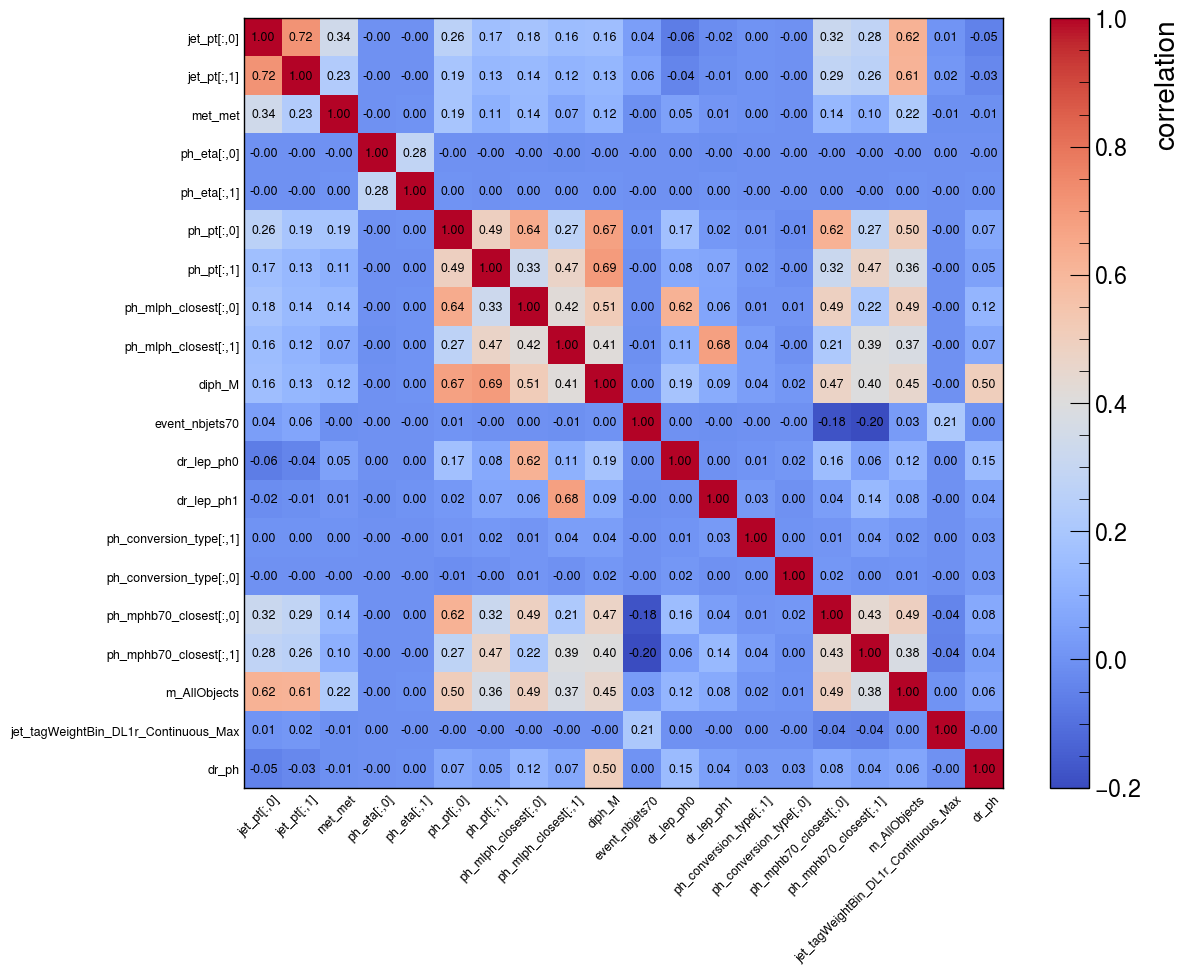

In [23]:
fig,ax = plt.subplots(figsize=(12, 10))  # Adjust width and height for desired size

# Create heatmap with coolwarm colormap and white background
corr = sig_corr_matrix.values  # Assuming sig_corr_matrix is your correlation matrix

# Create heatmap
heatmap = plt.imshow(corr, cmap='coolwarm', aspect='auto')

# Add colorbar
plt.colorbar(heatmap, label='correlation')

# Add white background to the plot area
ax.set_facecolor('white')  # 'gca' gets current axis

# Add annotations for each cell (replace '.1g' with desired format if needed)
for i in range(len(corr)):
    for j in range(len(corr[0])):
        plt.text(j, i, f"{corr[i, j]:.2f}", ha='center', va='center', fontsize=9)  # Adjust formatting

        
plt.xticks(rotation=45, ha='right', fontsize=9)  # Adjust rotation, alignment, and size
plt.yticks(fontsize=9)
ax.set_xticks(np.arange(len(feature_cols))+0.5,feature_cols)
ax.set_yticks(np.arange(len(feature_cols)),feature_cols)

plt.tick_params(which='both', bottom=False, top=False, left=False, right=False)  # Set visibility for all sides

plt.savefig('sig_correlation_heatmap_seaborn_large_white_Model6.png', dpi=500, bbox_inches='tight')


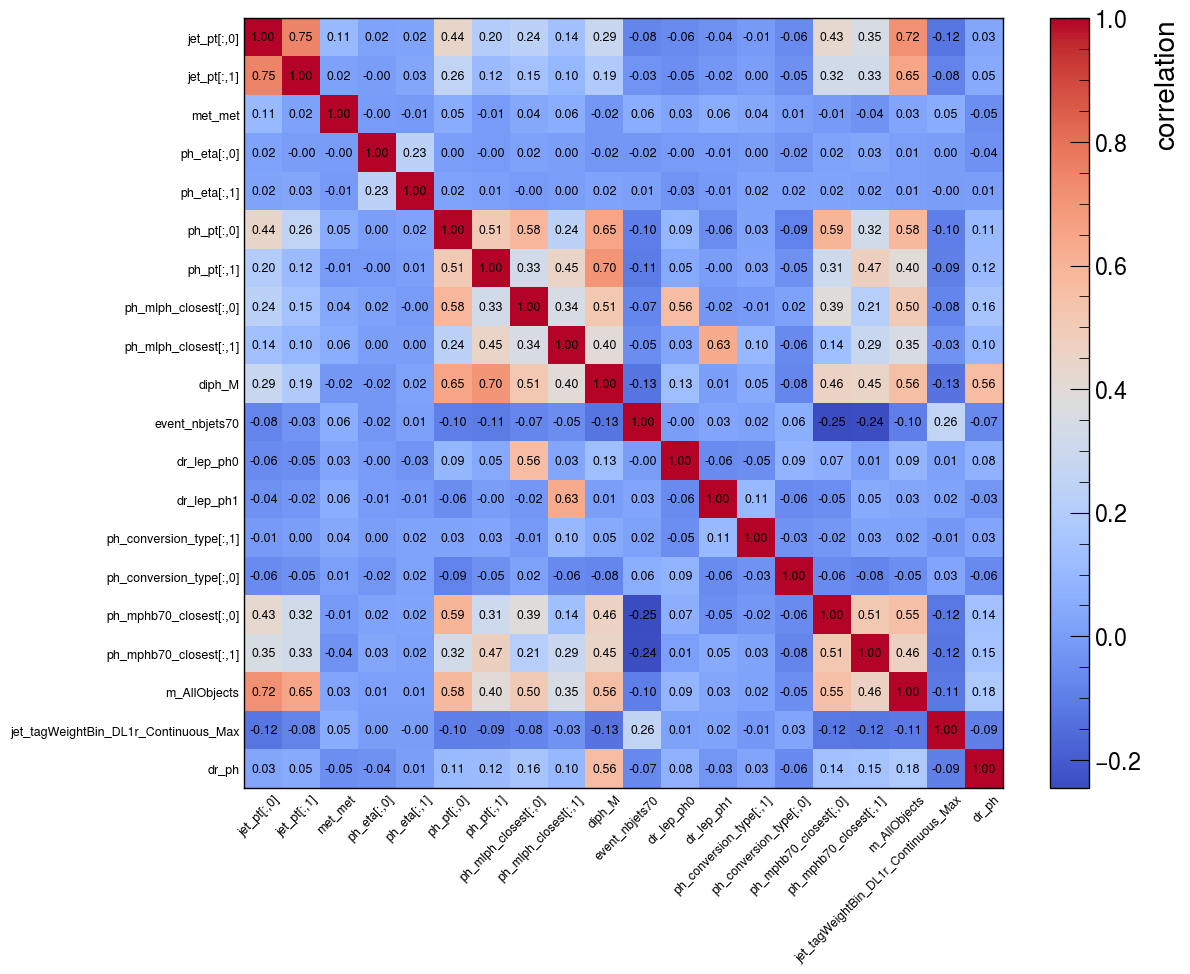

In [24]:
fig,ax = plt.subplots(figsize=(12, 10))  # Adjust width and height for desired size

# Create heatmap with coolwarm colormap and white background
corr = bkg_corr_matrix.values  # Assuming bkg_corr_matrix is your correlation matrix

# Create heatmap
heatmap = plt.imshow(corr, cmap='coolwarm', aspect='auto')

# Add colorbar
plt.colorbar(heatmap, label='correlation')

# Add white background to the plot area
ax.set_facecolor('white')  # 'gca' gets current axis

# Add annotations for each cell (replace '.1g' with desired format if needed)
for i in range(len(corr)):
    for j in range(len(corr[0])):
        plt.text(j, i, f"{corr[i, j]:.2f}", ha='center', va='center', fontsize=9)  # Adjust formatting

        
plt.xticks(rotation=45, ha='right', fontsize=9)  # Adjust rotation, alignment, and size
plt.yticks(fontsize=9)
ax.set_xticks(np.arange(len(feature_cols))+0.5,feature_cols)
ax.set_yticks(np.arange(len(feature_cols)),feature_cols)

plt.tick_params(which='both', bottom=False, top=False, left=False, right=False)  # Set visibility for all sides


plt.savefig('bkg_correlation_heatmap_seaborn_large_white_Model6.png', dpi=500, bbox_inches='tight')



In [45]:
print(len(corr))

5


In [32]:
xgboost.__version__

'2.0.2'